<div dir="rtl" align="right">
<h1>فاز دوم پروژه آمار: احتمال و توزیع‌های احتمالی 
<hr>
</div>

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", None)
sns.set_theme(style="whitegrid")

# ۱. بارگذاری و ادغام ۸ فایل موضوعی   
data_dir = Path("../data")

lux_df = pd.read_sas(data_dir / "LUX_L.xpt", format="xport")
lux_cols = [c for c in ["SEQN", "LUAXSTAT", "LUARXNC", "LUANMVGP", "LUXSMED", "LUXSIQR", "LUXSIQRM", "LUXCAPM"] if c in lux_df.columns]
df_merged = lux_df[lux_cols].copy()

other_files_vars = {
    "DEMO_L.xpt": ["SEQN", "RIDAGEYR", "RIAGENDR", "WTMEC2YR"],
    "CBC_L.xpt": ["SEQN", "LBDNENO", "LBDLYMNO"],
    "BMX_L.xpt": ["SEQN", "BMXBMI"],
    "BPXO_L.xpt": ["SEQN", "BPXOSY1"],
    "GHB_L.xpt": ["SEQN", "LBXGH"],
    "TCHOL_L.xpt": ["SEQN", "LBXTC"],
    "BIOPRO_L.xpt": ["SEQN", "LBXSATSI", "LBXSASSI"]
}

for fname, cols in other_files_vars.items():
    fpath = data_dir / fname
    temp_df = pd.read_sas(fpath, format="xport")[cols]
    df_merged = pd.merge(df_merged, temp_df, on="SEQN", how="right" if fname == "DEMO_L.xpt" else "left")

# ۲. محاسبه شاخص التهاب سیستمیک و اعمال فیلترهای پایه فاز اول
df_merged["NLR"] = np.where(
    df_merged["LBDLYMNO"] > 0,
    df_merged["LBDNENO"] / df_merged["LBDLYMNO"],
    np.nan
)

n_total = len(df_merged)
df_adults = df_merged[df_merged["RIDAGEYR"] >= 20].copy()
n_under20 = n_total - len(df_adults)

df_mec = df_adults[df_adults["WTMEC2YR"] > 0].copy()
n_no_mec = len(df_adults) - len(df_mec)

df_phase1 = df_mec.dropna(subset=["LUXSMED", "NLR"]).copy()
n_missing_main = len(df_mec) - len(df_phase1)

# ۳. اعمال ۳ پارامتر کنترل کیفیت الاستوگرافی کبد (ناشتایی، تعداد دفعات تست، واریانس/تغییرپذیری)
n_fasting_fail = int((df_phase1["LUARXNC"] == 1).sum())
n_measures_fail = int(df_phase1["LUANMVGP"].isin([1, 2]).sum())
n_var_fail = int((df_phase1["LUXSIQRM"] >= 30).sum())

cond_quality = (
    (df_phase1["LUAXSTAT"] == 1) &
    (~df_phase1["LUANMVGP"].isin([1, 2])) &
    (df_phase1["LUXSIQRM"] < 30)
)

df_qc = df_phase1[cond_quality].copy()
n_qc_dropped = len(df_phase1) - len(df_qc)

# ۴. حذف ردیف‌های دارای داده گمشده در متغیرهای فرعی و کنترلی
secondary_cols = ["LUXCAPM", "BMXBMI", "BPXOSY1", "LBXGH", "LBXTC", "LBXSATSI", "LBXSASSI"]
all_analysis_cols = ["RIDAGEYR", "RIAGENDR", "WTMEC2YR", "LUXSMED", "NLR"] + secondary_cols

df_clean = df_qc.dropna(subset=all_analysis_cols).copy().reset_index(drop=True)
n_sec_dropped = len(df_qc) - len(df_clean)

print("\n=== جریان گام‌به‌گام تعیین حجم نمونه تحلیلی نهایی (فاز دوم - موارد کاملاً بدون داده گمشده) ===")
print(f"\u202b۱. تعداد کل شرکت‌کنندگان پس از ادغام ۸ فایل: {n_total} نفر\u202c")
print(f"\u202b۲. حذف افراد زیر ۲۰ سال: {n_under20} نفر (باقی‌مانده بزرگسالان: {len(df_adults)} نفر)\u202c")
print(f"\u202b۳. حذف بزرگسالان فاقد وزن معاینه (WTMEC2YR = 0): {n_no_mec} نفر (باقی‌مانده: {len(df_mec)} نفر)\u202c")
print(f"\u202b۴. حذف به دلیل داده گمشده در متغیرهای اصلی (LUXSMED یا NLR): {n_missing_main} نفر (نمونه فاز اول: {len(df_phase1)} نفر)\u202c")
print(f"\u202b۵. حذف به دلیل عدم احراز ۳ پارامتر کیفیت الاستوگرافی کبد: {n_qc_dropped} نفر (باقی‌مانده باکیفیت: {len(df_qc)} نفر)\u202c")
print(f"\u202b   - پارامتر ۱ (زمان ناشتایی کمتر از ۳ ساعت | LUARXNC == 1): {n_fasting_fail} نفر\u202c")
print(f"\u202b   - پارامتر ۲ (تعداد اندازه‌گیری معتبر کمتر از ۱۰ بار): {n_measures_fail} نفر\u202c")
print(f"\u202b   - پارامتر ۳ (تغییرپذیری بالای اندازه‌گیری‌ها | IQR/Median >= 30%): {n_var_fail} نفر\u202c")
print(f"\u202b۶. حذف به دلیل داده گمشده در متغیرهای فرعی و کنترلی: {n_sec_dropped} نفر\u202c")
print(f"\u202b==> ۷. حجم نمونه تحلیلی نهایی و کاملاً بدون داده گمشده (df_clean): {len(df_clean)} نفر\u202c\n")


=== جریان گام‌به‌گام تعیین حجم نمونه تحلیلی نهایی (فاز دوم - موارد کاملاً بدون داده گمشده) ===
‫۱. تعداد کل شرکت‌کنندگان پس از ادغام ۸ فایل: 11933 نفر‬
‫۲. حذف افراد زیر ۲۰ سال: 4124 نفر (باقی‌مانده بزرگسالان: 7809 نفر)‬
‫۳. حذف بزرگسالان فاقد وزن معاینه (WTMEC2YR = 0): 0 نفر (باقی‌مانده: 7809 نفر)‬
‫۴. حذف به دلیل داده گمشده در متغیرهای اصلی (LUXSMED یا NLR): 2449 نفر (نمونه فاز اول: 5360 نفر)‬
‫۵. حذف به دلیل عدم احراز ۳ پارامتر کیفیت الاستوگرافی کبد: 319 نفر (باقی‌مانده باکیفیت: 5041 نفر)‬
‫   - پارامتر ۱ (زمان ناشتایی کمتر از ۳ ساعت | LUARXNC == 1): 100 نفر‬
‫   - پارامتر ۲ (تعداد اندازه‌گیری معتبر کمتر از ۱۰ بار): 17 نفر‬
‫   - پارامتر ۳ (تغییرپذیری بالای اندازه‌گیری‌ها | IQR/Median >= 30%): 179 نفر‬
‫۶. حذف به دلیل داده گمشده در متغیرهای فرعی و کنترلی: 427 نفر‬
‫==> ۷. حجم نمونه تحلیلی نهایی و کاملاً بدون داده گمشده (df_clean): 4614 نفر‬



<div dir="rtl" align="right">
<h3>جمع‌بندی آماده‌سازی داده، تعیین حجم نمونه نهایی و علت حذف داده‌های گمشده</h3>
در فاز اول پروژه، با اعمال شرط سنی (بزرگسالان ۲۰ سال و بالاتر)، داشتن وزن معاینه معتبر (<code>WTMEC2YR > 0</code>) و حذف مقادیر گمشده در دو متغیر اصلی (<code>LUXSMED</code> و <code>NLR</code>)، نمونه اولیه شامل ۵,۳۶۰ شرکت‌کننده به دست آمد.<br><br>
به منظور افزایش دقت اندازه‌گیری و یکدست‌سازی کامل فضای نمونه در تمامی تحلیل‌ها، دو مرحله پالایش تکمیلی اعمال گردید:<br>
<b>۱. اعمال معیارهای کنترل کیفیت الاستوگرافی کبد:</b> ۳۱۹ مشاهده که فاقد معیارهای کیفیت معاینه کامل (<code>LUAXSTAT == 1</code>) بودند — به دلیل ناشتایی کمتر از ۳ ساعت (<code>LUARXNC == 1</code> شامل ۱۰۰ نفر)، تعداد دفعات اندازه‌گیری معتبر کمتر از ۱۰ بار (<code>LUANMVGP</code> با کدهای ۱ و ۲ شامل ۱۷ نفر) یا تغییرپذیری و واریانس بالای اندازه‌گیری‌ها (<code>LUXSIQRM >= 30%</code> شامل ۱۷۹ نفر) — کنار گذاشته شدند تا ۵,۰۴۱ مشاهده باکیفیت باقی بمانند.<br>
<b>۲. حذف کامل مقادیر گمشده در متغیرهای فرعی و کنترلی:</b> به منظور انجام تحلیل موارد کامل روی یک فضای نمونه واحد، ۴۲۷ مشاهده که در هر یک از متغیرهای فرعی (<code>LUXCAPM</code>، <code>BMXBMI</code>، <code>BPXOSY1</code>، <code>LBXGH</code>، <code>LBXTC</code>، <code>LBXSATSI</code> و <code>LBXSASSI</code>) دارای مقدار گمشده بودند نیز حذف گردیدند تا در مجموعه داده تحلیلی نهایی (<code>df_clean</code>) هیچ مقدار گمشده‌ای در هیچ متغیری وجود نداشته باشد.<br><br>
<b>دلایل آماری و علمی حذف داده‌های گمشده (روش تحلیل موارد کامل):</b><br>
• <b>یکپارچگی فضای نمونه (Ω) در نظریه احتمال:</b> در محاسبات فاز دوم (شامل احتمال‌های حاشیه‌ای، مشترک، شرطی، قضیه بیز و کوواریانس)، تمامی رویدادها و متغیرهای تصادفی باید بر روی یک فضای نمونه واحد و ثابت تعریف شوند. وجود داده‌های گمشده باعث تغییر مخرج کسر (N) از یک متغیر به متغیر دیگر شده و سازگاری ریاضی روابط احتمالی (مانند <code>P(A ∩ B)</code> و قانون احتمال کل) را مختل می‌کند.<br>
• <b>جلوگیری از اریبی و تحریف توزیع واقعی داده ها :</b> در متغیرهای زیستی و آزمایشگاهی (مانند سفتی کبد، شاخص التهاب و آنزیم‌های کبدی)، جایگذاری مقادیر گمشده با مقادیر مصنوعی (نظیر میانگین یا میانه) باعث کاهش کاذب واریانس، تغییر شکل واقعی چولگی توزیع‌ها و ایجاد خطا در برآورد احتمال رویدادهای حدی و رابطه واقعی بین متغیرها می‌شود.<br>
• <b>کفایت بالای حجم نمونه باقی‌مانده:</b> پس از حذف موارد ناقص، حجم نمونه ۴,۶۱۴ نفری همچنان بسیار بزرگ بوده و از توان و دقت آماری کاملاً کافی برای محاسبه دقیق احتمال ها و شاخص های آماری برخوردار است.
<hr>
</div>

<div dir="rtl" align="right">
<h2>تسک مشترک ۱: تعریف رویدادها و متغیرهای تصادفی</h2>
<b>تعریف واحد مشاهده و فضای نمونه (Ω):</b><br> پس از اعمال فیلترهای کنترل کیفیت الاستوگرافی کبد و حذف کامل تمامی مقادیر گمشده ، فضای نمونه شامل <b>۴,۶۱۴ ردیف</b> موجود در مجموعه داده تحلیلی نهایی (<code>df_clean</code>) است. هر <b>مشاهده</b> در این فضای نمونه، دقیقاً متناظر با <b>یک شرکت‌کننده بزرگسال مستقل (۲۰ سال و بالاتر) دارای معاینه معتبر در پیمایش NHANES (۲۰۲۱–۲۰۲۳)</b> است که در مجموعه داده با شناسه یکتای <code>SEQN</code> در یک سطر مجزا مشخص می‌شود.<br><br>
<b>الف) تعریف رویدادهای تصادفی :</b><br>
• <b>رویداد A (ابتلا به فیبروز پیشرفته کبدی - Advanced Fibrosis):</b> شامل تمام مشاهداتی (ردیف‌هایی با شناسه <code>SEQN</code>) است که در ستون سفتی کبد (<code>LUXSMED</code> از فایل <code>LUX_L</code>) دارای مقدار برابر یا بیشتر از آستانه بالینی ۸.۲ کیلوپاسکال باشند (<code>LUXSMED >= 8.2</code>). وقوع این رویداد در دیتافریم با ستون دودویی <code>Event_A_Fibrosis</code> (مقدار <code>1</code> برای وقوع و <code>0</code> برای عدم وقوع در آن مشاهده) ثبت شده است.<br>
• <b>رویداد B (التهاب سیستمیک بالا - High NLR):</b> شامل تمام مشاهداتی (ردیف‌هایی با شناسه <code>SEQN</code>) است که در متغیر نسبت نوتروفیل به لنفوسیت (<code>NLR</code> حاصل از فایل <code>CBC_L</code>) دارای مقدار برابر یا بیشتر از آستانه بالینی ۳.۰ باشند (<code>NLR >= 3.0</code>). این رویداد با ستون دودویی <code>Event_B_HighNLR</code> (مقدار <code>1</code> برای وقوع و <code>0</code> برای عدم وقوع) مشخص می‌شود.<br>
• <b>رویدادهای زیرگروهی G (جنسیت مرد) و S (سالمندی ۶۰ سال و بالاتر):</b> برای تحلیل احتمال‌های شرطی در زیرگروه‌ها، رویداد <code>G</code> شامل مشاهداتی است که در ستون <code>RIAGENDR</code> دارای کد <code>1</code> (مرد) هستند (<code>Event_G_Male</code>) و رویداد <code>S</code> شامل مشاهداتی است که در ستون سن (<code>RIDAGEYR</code>) دارای مقدار ۶۰ سال و بالاتر هستند (<code>Event_S_Senior</code>).<br><br>
<b>ب) تعریف متغیرهای تصادفی :</b><br>
• <b>متغیر تصادفی پیوسته Y (سفتی کبد):</b> تابعی است که به هر مشاهده (شرکت‌کننده با شناسه <code>SEQN</code>)، مقدار عددی پیوسته ثبت‌شده در ستون <code>LUXSMED</code> همان ردیف را بر حسب کیلوپاسکال (<code>kPa</code>) نسبت می‌دهد.<br>
• <b>متغیر تصادفی پیوسته X (شاخص التهاب سیستمیک):</b> تابعی است که به هر مشاهده (شرکت‌کننده با شناسه <code>SEQN</code>)، مقدار عددی پیوسته ثبت‌شده در ستون <code>NLR</code> همان ردیف را نسبت می‌دهد.<br>
• <b>متغیر تصادفی گسسته برنولی I_A (نشانگر فیبروز پیشرفته):</b> تابعی گسسته با مقادیر <code>{0, 1}</code> است که به هر مشاهده (ردیف <code>SEQN</code>) در صورت وقوع رویداد فیبروز پیشرفته (<code>LUXSMED >= 8.2</code>) عدد <code>1</code> و در غیر این صورت عدد <code>0</code> را نسبت می‌دهد.
</div>

In [12]:
# ۱. تعریف ستون‌های نشانگر (0 و 1) برای رویدادها به ازای هر مشاهده (SEQN) در df_clean
df_clean["Event_A_Fibrosis"] = (df_clean["LUXSMED"] >= 8.2).astype(int)
df_clean["Event_B_HighNLR"] = (df_clean["NLR"] >= 3.0).astype(int)
df_clean["Event_G_Male"] = (df_clean["RIAGENDR"] == 1).astype(int)
df_clean["Event_S_Senior"] = (df_clean["RIDAGEYR"] >= 60).astype(int)

# ۲. جدول خلاصه رویدادها و متغیرهای تصادفی در فضای نمونه ۴۶۱۴ نفری
task1_summary = pd.DataFrame({
    "نماد و عنوان در مدل احتمالی": [
        "رویداد A / متغیر برنولی I_A (فیبروز پیشرفته کبدی)",
        "رویداد B / متغیر برنولی I_B (التهاب سیستمیک بالا)",
        "رویداد G (زیرگروه جنسیت مرد)",
        "رویداد S (زیرگروه سنی ۶۰ سال و بالاتر)",
        "متغیر تصادفی پیوسته Y (سفتی کبد)",
        "متغیر تصادفی پیوسته X (شاخص التهاب سیستمیک)"
    ],
    "ستون و شرط متناظر در هر ردیف داده (SEQN)": [
        "LUXSMED >= 8.2 kPa (ستون Event_A_Fibrosis)",
        "NLR >= 3.0 (ستون Event_B_HighNLR)",
        "RIAGENDR == 1 (ستون Event_G_Male)",
        "RIDAGEYR >= 60 (ستون Event_S_Senior)",
        "مقدار کمی ستون LUXSMED (بر حسب kPa)",
        "مقدار کمی ستون NLR (نسبت نوتروفیل به لنفوسیت)"
    ],
    "نوع در نظریه احتمال": [
        "رویداد طبقه‌ای / متغیر گسسته دودویی (0 و 1)",
        "رویداد طبقه‌ای / متغیر گسسته دودویی (0 و 1)",
        "رویداد طبقه‌ای دودویی (0 و 1)",
        "رویداد طبقه‌ای دودویی (0 و 1)",
        "متغیر تصادفی کمی پیوسته",
        "متغیر تصادفی کمی پیوسته"
    ],
    "تعداد کل مشاهدات (N)": [len(df_clean)] * 6,
    "فراوانی وقوع (کد 1) یا دامنه مقادیر": [
        f"{int(df_clean['Event_A_Fibrosis'].sum())} نفر ({df_clean['Event_A_Fibrosis'].mean()*100:.2f}%)",
        f"{int(df_clean['Event_B_HighNLR'].sum())} نفر ({df_clean['Event_B_HighNLR'].mean()*100:.2f}%)",
        f"{int(df_clean['Event_G_Male'].sum())} نفر ({df_clean['Event_G_Male'].mean()*100:.2f}%)",
        f"{int(df_clean['Event_S_Senior'].sum())} نفر ({df_clean['Event_S_Senior'].mean()*100:.2f}%)",
        f"دامنه: [{df_clean['LUXSMED'].min():.1f} تا {df_clean['LUXSMED'].max():.1f}] | میانگین: {df_clean['LUXSMED'].mean():.2f}",
        f"دامنه: [{df_clean['NLR'].min():.2f} تا {df_clean['NLR'].max():.2f}] | میانگین: {df_clean['NLR'].mean():.2f}"
    ]
})

print(f"\u202b--- ۱. جدول مشخصات رویدادها و متغیرهای تصادفی در فضای نمونه نهایی (N = {len(df_clean)}) ---\u202c")
display(task1_summary)

# ۳. نمایش مصداق عینی از مشاهدات واقعی داده (بر اساس شناسه SEQN)
sample_obs = df_clean[[
    "SEQN", "RIDAGEYR", "RIAGENDR", "LUXSMED", "NLR",
    "Event_A_Fibrosis", "Event_B_HighNLR", "Event_G_Male", "Event_S_Senior"
]].head(6).copy()

sample_obs["SEQN"] = sample_obs["SEQN"].astype(int)
sample_obs["RIDAGEYR"] = sample_obs["RIDAGEYR"].astype(int)
sample_obs["RIAGENDR"] = sample_obs["RIAGENDR"].map({1: "مرد (1)", 2: "زن (2)"})
sample_obs["NLR"] = sample_obs["NLR"].round(2)

sample_obs.columns = [
    "شناسه مشاهده (SEQN)",
    "سن (RIDAGEYR)",
    "جنسیت (RIAGENDR)",
    "متغیر پیوسته Y (LUXSMED)",
    "متغیر پیوسته X (NLR)",
    "وقوع رویداد A (فیبروز >= 8.2)",
    "وقوع رویداد B (التهاب >= 3.0)",
    "وقوع رویداد G (مرد)",
    "وقوع رویداد S (سن >= 60)"
]

print(f"\n\u202b--- ۲. نمونه عینی تناظر مشاهدات داده (ردیف‌های SEQN) با مقادیر متغیرهای تصادفی و وقوع رویدادها ---\u202c")
display(sample_obs)

‫--- ۱. جدول مشخصات رویدادها و متغیرهای تصادفی در فضای نمونه نهایی (N = 4614) ---‬


,نماد و عنوان در مدل احتمالی,ستون و شرط متناظر در هر ردیف داده (SEQN),نوع در نظریه احتمال,تعداد کل مشاهدات (N),فراوانی وقوع (کد 1) یا دامنه مقادیر
0,رویداد A / متغیر برنولی I_A (فیبروز پیشرفته کبدی),LUXSMED >= 8.2 kPa (ستون Event_A_Fibrosis),رویداد طبقه‌ای / متغیر گسسته دودویی (0 و 1),4614,538 نفر (11.66%)
1,رویداد B / متغیر برنولی I_B (التهاب سیستمیک بالا),NLR >= 3.0 (ستون Event_B_HighNLR),رویداد طبقه‌ای / متغیر گسسته دودویی (0 و 1),4614,769 نفر (16.67%)
2,رویداد G (زیرگروه جنسیت مرد),RIAGENDR == 1 (ستون Event_G_Male),رویداد طبقه‌ای دودویی (0 و 1),4614,2108 نفر (45.69%)
3,رویداد S (زیرگروه سنی ۶۰ سال و بالاتر),RIDAGEYR >= 60 (ستون Event_S_Senior),رویداد طبقه‌ای دودویی (0 و 1),4614,2061 نفر (44.67%)
4,متغیر تصادفی پیوسته Y (سفتی کبد),مقدار کمی ستون LUXSMED (بر حسب kPa),متغیر تصادفی کمی پیوسته,4614,دامنه: [1.5 تا 75.0] | میانگین: 6.13
5,متغیر تصادفی پیوسته X (شاخص التهاب سیستمیک),مقدار کمی ستون NLR (نسبت نوتروفیل به لنفوسیت),متغیر تصادفی کمی پیوسته,4614,دامنه: [0.30 تا 16.00] | میانگین: 2.20



‫--- ۲. نمونه عینی تناظر مشاهدات داده (ردیف‌های SEQN) با مقادیر متغیرهای تصادفی و وقوع رویدادها ---‬


,شناسه مشاهده (SEQN),سن (RIDAGEYR),جنسیت (RIAGENDR),متغیر پیوسته Y (LUXSMED),متغیر پیوسته X (NLR),وقوع رویداد A (فیبروز >= 8.2),وقوع رویداد B (التهاب >= 3.0),وقوع رویداد G (مرد),وقوع رویداد S (سن >= 60)
0,130378,43,مرد (1),9.5,1.16,1,0,1,0
1,130379,66,مرد (1),3.9,2.25,0,0,1,1
2,130380,44,زن (2),7.6,1.94,0,0,0,0
3,130386,34,مرد (1),3.1,0.67,0,0,1,0
4,130391,33,زن (2),3.9,2.52,0,0,0,0
5,130392,74,زن (2),5.7,1.88,0,0,0,1


<div dir="rtl" align="right">
<b>جمع‌بندی خروجی تسک مشترک ۱:</b><br>
بر اساس نتایج جدول فوق بر روی فضای نمونه نهایی (<code>N = 4,614</code>)، متغیر پیوسته سفتی کبد (<code>Y</code>) در بازه ۱.۵ تا ۷۵.۰ کیلوپاسکال با میانگین ۶.۱۳ کیلوپاسکال قرار دارد که در آن <b>۵۳۸ نفر (۱۱.۶۶٪)</b> دچار رویداد فیبروز پیشرفته کبدی (<code>A</code>) هستند. همچنین متغیر پیوسته شاخص التهاب سیستمیک (<code>X</code>) دارای میانگین ۲.۲۰ است و رویداد التهاب سیستمیک بالا (<code>B</code>) در <b>۷۶۹ نفر (۱۶.۶۷٪)</b> رخ داده است. از نظر زیرگروه‌های جمعیتی نیز ۴۵.۶۹٪ نمونه را مردان (<code>G</code>) و ۴۴.۶۷٪ را سالمندان ۶۰ سال و بالاتر (<code>S</code>) تشکیل می‌دهند.
<hr>
</div>

<div dir="rtl" align="right">
<h2>تسک مشترک ۲ : احتمال‌های حاشیه‌ای و مشترک</h2>
در این مرحله، بر روی فضای نمونه نهایی (<code>N = 4,614</code>)، توزیع احتمال حاشیه‌ای و مشترک دو رویداد اصلی پژوهش یعنی <b>رویداد A (ابتلا به فیبروز پیشرفته کبدی: <code>LUXSMED >= 8.2</code>)</b> و <b>رویداد B (التهاب سیستمیک بالا: <code>NLR >= 3.0</code>)</b> محاسبه و بررسی می‌شود:<br><br>
• <b>احتمال حاشیه‌ای :</b> احتمال وقوع هر یک از رویدادها به تنهایی و بدون در نظر گرفتن وضعیت رویداد دیگر در کل فضای نمونه است؛ یعنی <code>P(A) = n_A / N</code> و <code>P(B) = n_B / N</code>.<br>
• <b>احتمال مشترک :</b> احتمال وقوع هم‌زمان دو رویداد در یک مشاهده واحد است؛ برای نمونه <code>P(A ∩ B) = n_(A ∩ B) / N</code> نشان‌دهنده احتمال آن است که یک فرد به طور هم‌زمان هم دارای التهاب سیستمیک بالا و هم مبتلا به فیبروز پیشرفته کبدی باشد.<br>
• <b>مقایسه احتمال خام (نمونه) و وزن‌دار (جمعیت):</b> با توجه به طراحی نمونه‌گیری پیمایش NHANES، علاوه بر احتمال تجربی خام در نمونه، احتمال وزن‌دار با استفاده از وزن معاینه پزشکی (<code>WTMEC2YR</code>) نیز محاسبه می‌شود تا برآوردهای نمونه با جمعیت هدف بزرگسالان مقایسه گردد.
</div>

In [13]:
A = df_clean["Event_A_Fibrosis"]
B = df_clean["Event_B_HighNLR"]
w = df_clean["WTMEC2YR"]

# ۱. جدول توافقی فراوانی مطلق (تعداد افراد در هر زیرگروه)
ct_counts = pd.crosstab(
    A.map({1: "وقوع A (فیبروز پیشرفته: کد 1)", 0: "عدم وقوع A (بدون فیبروز: کد 0)"}),
    B.map({1: "وقوع B (التهاب بالا: کد 1)", 0: "عدم وقوع B (التهاب عادی: کد 0)"}),
    margins=True, margins_name="جمع حاشیه‌ای (کل)"
)

# ۲. جدول احتمال‌های مشترک و حاشیه‌ای (تقسیم فراوانی‌ها بر کل نمونه ۴۶۱۴ نفری)
ct_probs = pd.crosstab(
    A.map({1: "وقوع A (فیبروز پیشرفته: کد 1)", 0: "عدم وقوع A (بدون فیبروز: کد 0)"}),
    B.map({1: "وقوع B (التهاب بالا: کد 1)", 0: "عدم وقوع B (التهاب عادی: کد 0)"}),
    margins=True, margins_name="احتمال حاشیه‌ای (کل)", normalize="all"
).round(4)

print(f"\u202b--- ۱. جدول توافقی فراوانی مشاهدات در فضای نمونه (N = {len(df_clean)}) ---\u202c")
display(ct_counts)

print("\n\u202b--- ۲. جدول احتمال‌های مشترک P(A ∩ B) و احتمال‌های حاشیه‌ای P(A) و P(B) ---\u202c")
display(ct_probs)

# ۳. مقایسه احتمال تجربی خام (بدون وزن) و وزن‌دار (با وزن WTMEC2YR)
def calc_weighted_prob(event_series, weights):
    return np.sum(event_series * weights) / np.sum(weights)

events_dict = {
    "P(A): احتمال حاشیه‌ای فیبروز پیشرفته (LUXSMED >= 8.2)": A,
    "P(B): احتمال حاشیه‌ای التهاب بالا (NLR >= 3.0)": B,
    "P(A ∩ B): احتمال مشترک فیبروز پیشرفته و التهاب بالا": (A & B),
    "P(A ∩ B'): احتمال مشترک فیبروز پیشرفته و التهاب عادی": (A & (1 - B)),
    "P(A' ∩ B): احتمال مشترک نبود فیبروز و التهاب بالا": ((1 - A) & B),
    "P(A' ∩ B'): احتمال مشترک نبود فیبروز و التهاب عادی": ((1 - A) & (1 - B))
}

rows_prob = []
for label, ev in events_dict.items():
    p_raw = ev.mean()
    p_wt = calc_weighted_prob(ev, w)
    rows_prob.append({
        "رویداد احتمالی": label,
        "تعداد وقوع (n)": int(ev.sum()),
        "احتمال خام (نمونه)": round(p_raw, 4),
        "درصد خام (%)": round(p_raw * 100, 2),
        "احتمال وزن‌دار (جمعیت)": round(p_wt, 4),
        "درصد وزن‌دار (%)": round(p_wt * 100, 2),
        "اختلاف درصد (وزن‌دار - خام)": round((p_wt - p_raw) * 100, 2)
    })

df_prob_compare = pd.DataFrame(rows_prob)
print("\n\u202b--- ۳. مقایسه احتمال‌های حاشیه‌ای و مشترک به دو روش خام (نمونه) و وزن‌دار (جمعیت) ---\u202c")
display(df_prob_compare)

‫--- ۱. جدول توافقی فراوانی مشاهدات در فضای نمونه (N = 4614) ---‬


Event_B_HighNLR,عدم وقوع B (التهاب عادی: کد 0),وقوع B (التهاب بالا: کد 1),جمع حاشیه‌ای (کل)
Event_A_Fibrosis,,,
عدم وقوع A (بدون فیبروز: کد 0),3419,657,4076
وقوع A (فیبروز پیشرفته: کد 1),426,112,538
جمع حاشیه‌ای (کل),3845,769,4614



‫--- ۲. جدول احتمال‌های مشترک P(A ∩ B) و احتمال‌های حاشیه‌ای P(A) و P(B) ---‬


Event_B_HighNLR,عدم وقوع B (التهاب عادی: کد 0),وقوع B (التهاب بالا: کد 1),احتمال حاشیه‌ای (کل)
Event_A_Fibrosis,,,
عدم وقوع A (بدون فیبروز: کد 0),0.7410,0.1424,0.8834
وقوع A (فیبروز پیشرفته: کد 1),0.0923,0.0243,0.1166
احتمال حاشیه‌ای (کل),0.8333,0.1667,1.0000



‫--- ۳. مقایسه احتمال‌های حاشیه‌ای و مشترک به دو روش خام (نمونه) و وزن‌دار (جمعیت) ---‬


,رویداد احتمالی,تعداد وقوع (n),احتمال خام (نمونه),درصد خام (%),احتمال وزن‌دار (جمعیت),درصد وزن‌دار (%),اختلاف درصد (وزن‌دار - خام)
0,P(A): احتمال حاشیه‌ای فیبروز پیشرفته (LUXSMED >= 8.2),538,0.1166,11.66,0.1104,11.04,-0.62
1,P(B): احتمال حاشیه‌ای التهاب بالا (NLR >= 3.0),769,0.1667,16.67,0.1514,15.14,-1.52
2,P(A ∩ B): احتمال مشترک فیبروز پیشرفته و التهاب بالا,112,0.0243,2.43,0.0244,2.44,0.01
3,P(A ∩ B'): احتمال مشترک فیبروز پیشرفته و التهاب عادی,426,0.0923,9.23,0.0860,8.60,-0.63
4,P(A' ∩ B): احتمال مشترک نبود فیبروز و التهاب بالا,657,0.1424,14.24,0.1271,12.71,-1.53
5,P(A' ∩ B'): احتمال مشترک نبود فیبروز و التهاب عادی,3419,0.7410,74.10,0.7625,76.25,2.15


<div dir="rtl" align="right">
<b>تحلیل و جمع‌بندی نتایج تسک مشترک ۲ (بر روی نمونه کنترل‌کیفیت‌شده N = 4,614):</b><br>
پس از پالایش داده‌ها بر اساس سه معیار کیفیت دستگاه فیبرواسکن (حداقل ۳ ساعت ناشتایی، ثبت حداقل ۱۰ اندازه‌گیری معتبر و نسبت <code>IQR/Median</code> کمتر از ۳۰ درصد)، توزیع احتمال حاشیه‌ای و مشترک رویدادها نشان می‌دهد:<br>
• <b>احتمال‌های حاشیه‌ای:</b> در نمونه نهایی، احتمال ابتلا به فیبروز پیشرفته کبدی <code>P(A) = 0.1166</code> (معادل <b>۱۱.۶۶٪</b> یا ۵۳۸ نفر) و احتمال داشتن التهاب سیستمیک بالا <code>P(B) = 0.1667</code> (معادل <b>۱۶.۶۷٪</b> یا ۷۶۹ نفر) است. در مقابل، ۸۸.۳۴٪ افراد فاقد فیبروز پیشرفته و ۸۳.۳۳٪ دارای سطح التهاب عادی هستند.<br>
• <b>احتمال‌های مشترک:</b> احتمال اینکه یک بزرگسال به طور هم‌زمان هم دارای التهاب سیستمیک بالا و هم مبتلا به فیبروز پیشرفته کبدی باشد برابر با <code>P(A ∩ B) = 0.0243</code> (معادل <b>۲.۴۳٪</b> یا ۱۱۲ نفر) است. همچنین <b>۷۴.۱۰٪</b> افراد (۳,۴۱۹ نفر) به طور هم‌زمان فاقد هر دو عارضه هستند (<code>P(A' ∩ B') = 0.7410</code>).<br>
• <b>مقایسه احتمال خام و وزن‌دار (تأثیر وزن معاینه <code>WTMEC2YR</code>):</b> پس از اعمال وزن‌های نمونه‌گیری جامعه، احتمال حاشیه‌ای فیبروز پیشرفته در جمعیت بزرگسالان برابر با <b>۱۱.۰۴٪</b> (۰.۶۲٪ کمتر از نمونه خام) و احتمال التهاب سیستمیک بالا برابر با <b>۱۵.۱۴٪</b> (۱.۵۲٪ کمتر از نمونه خام) برآورد می‌شود. علت بالاتر بودن جزئی درصدهای خام در نمونه این است که در طراحی پیمایش NHANES، گروه‌های سنی سالمند و پرخطر با نرخ بیشتری نمونه‌گیری می‌شوند؛ با این حال، احتمال مشترک <code>P(A ∩ B)</code> در هر دو حالت خام (۲.۴۳٪) و وزن‌دار (۲.۴۴٪) تقریباً یکسان و پایدار است.
<hr>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right; font-weight: normal;">
<h2 style="font-weight: bold;">تسک مشترک ۳: احتمال شرطی</h2>
در این بخش، با استفاده از تعریف احتمال شرطی <code>P(A | B) = P(A ∩ B) / P(B)</code>، بررسی می‌کنیم که چگونه آگاهی از وضعیت التهاب سیستمیک فرد (رویداد <code>B</code>) و یا قرار گرفتن در زیرگروه‌های جمعیتی (جنسیت مرد <code>G</code> و سالمندی <code>S</code>)، احتمال ابتلا به فیبروز پیشرفته کبدی (رویداد <code>A</code>) را تغییر می‌دهد.
</div>

In [14]:
# محاسبه احتمال‌های شرطی اصلی و زیرگروهی در نمونه کنترل‌کیفیت‌شده (N = 4614)
G = df_clean["Event_G_Male"]
S = df_clean["Event_S_Senior"]

p_A = A.mean()
p_B = B.mean()
p_AB = (A & B).mean()

# احتمال‌های شرطی فیبروز پیشرفته (A) به شرط سطوح مختلف التهاب (B) و زیرگروه‌ها
p_A_given_B = A[B == 1].mean()       # P(A | B)
p_A_given_notB = A[B == 0].mean()    # P(A | B')
p_B_given_A = B[A == 1].mean()       # P(B | A)
p_B_given_notA = B[A == 0].mean()    # P(B | A')

p_A_given_G = A[G == 1].mean()       # P(A | Male)
p_A_given_notG = A[G == 0].mean()    # P(A | Female)
p_A_given_S = A[S == 1].mean()       # P(A | Age >= 60)
p_A_given_notS = A[S == 0].mean()    # P(A | Age < 60)

cond_table = pd.DataFrame({
    "نماد احتمال شرطی": [
        "P(A) [احتمال حاشیه‌ای پایه در کل نمونه]",
        "P(A | B) [فیبروز به شرط التهاب بالا NLR >= 3.0]",
        "P(A | B') [فیبروز به شرط التهاب عادی NLR < 3.0]",
        "P(B | A) [التهاب بالا به شرط داشتن فیبروز پیشرفته]",
        "P(B | A') [التهاب بالا به شرط نداشتن فیبروز پیشرفته]",
        "P(A | G) [فیبروز به شرط جنسیت مرد]",
        "P(A | G') [فیبروز به شرط جنسیت زن]",
        "P(A | S) [فیبروز به شرط سالمندی >= ۶۰ سال]",
        "P(A | S') [فیبروز به شرط سن کمتر از ۶۰ سال]"
    ],
    "تعداد در مخرج (شرط)": [
        len(df_clean),
        int((B == 1).sum()),
        int((B == 0).sum()),
        int((A == 1).sum()),
        int((A == 0).sum()),
        int((G == 1).sum()),
        int((G == 0).sum()),
        int((S == 1).sum()),
        int((S == 0).sum())
    ],
    "تعداد وقوع در صورت (اشتراک)": [
        int(A.sum()),
        int((A & (B == 1)).sum()),
        int((A & (B == 0)).sum()),
        int((B & (A == 1)).sum()),
        int((B & (A == 0)).sum()),
        int((A & (G == 1)).sum()),
        int((A & (G == 0)).sum()),
        int((A & (S == 1)).sum()),
        int((A & (S == 0)).sum())
    ],
    "مقدار احتمال": np.round([
        p_A, p_A_given_B, p_A_given_notB,
        p_B_given_A, p_B_given_notA,
        p_A_given_G, p_A_given_notG,
        p_A_given_S, p_A_given_notS
    ], 4),
    "درصد (%)": np.round(np.array([
        p_A, p_A_given_B, p_A_given_notB,
        p_B_given_A, p_B_given_notA,
        p_A_given_G, p_A_given_notG,
        p_A_given_S, p_A_given_notS
    ]) * 100, 2)
})

print("\u202b--- جدول احتمال‌های شرطی رویدادها و زیرگروه‌های جمعیتی ---\u202c")
display(cond_table)

‫--- جدول احتمال‌های شرطی رویدادها و زیرگروه‌های جمعیتی ---‬


,نماد احتمال شرطی,تعداد در مخرج (شرط),تعداد وقوع در صورت (اشتراک),مقدار احتمال,درصد (%)
0,P(A) [احتمال حاشیه‌ای پایه در کل نمونه],4614,538,0.1166,11.66
1,P(A | B) [فیبروز به شرط التهاب بالا NLR >= 3.0],769,112,0.1456,14.56
2,P(A | B') [فیبروز به شرط التهاب عادی NLR < 3.0],3845,426,0.1108,11.08
3,P(B | A) [التهاب بالا به شرط داشتن فیبروز پیشرفته],538,112,0.2082,20.82
4,P(B | A') [التهاب بالا به شرط نداشتن فیبروز پیشرفته],4076,657,0.1612,16.12
5,P(A | G) [فیبروز به شرط جنسیت مرد],2108,283,0.1343,13.43
6,P(A | G') [فیبروز به شرط جنسیت زن],2506,255,0.1018,10.18
7,P(A | S) [فیبروز به شرط سالمندی >= ۶۰ سال],2061,274,0.1329,13.29
8,P(A | S') [فیبروز به شرط سن کمتر از ۶۰ سال],2553,264,0.1034,10.34


<div dir="rtl" align="right" style="direction: rtl; text-align: right; font-weight: normal;">
<b style="font-weight: bold;">تحلیل نتایج تسک مشترک ۳ (احتمال‌های شرطی):</b><br>
بررسی احتمال‌های شرطی بر روی ۴,۶۱۴ مشاهده دارای معاینه الاستوگرافی معتبر (با رعایت شروط ناشتایی حداقل ۳ ساعت، حداقل ۱۰ بار تست موفق و تغییرپذیری کمتر از ۳۰٪) نشان می‌دهد:<br><br>
• <b style="font-weight: bold;">تأثیر التهاب سیستمیک بر خطر فیبروز کبدی:</b> احتمال پایه ابتلا به فیبروز پیشرفته در کل نمونه ۱۱.۶۶٪ است؛ اما به شرط وجود التهاب سیستمیک بالا (<code>NLR >= 3.0</code>)، احتمال ابتلا به فیبروز پیشرفته به <code>P(A | B) = 14.56%</code> (۱۱۲ نفر از ۷۶۹ نفر) افزایش می‌یابد. در مقابل، در افراد دارای التهاب عادی این احتمال به <code>P(A | B') = 11.08%</code> (۴۲۶ نفر از ۳,۸۴۵ نفر) کاهش پیدا می‌کند.<br>
• <b style="font-weight: bold;">بررسی معکوس شرطی:</b> در میان افراد مبتلا به فیبروز پیشرفته کبدی، احتمال مشاهده التهاب سیستمیک بالا <code>P(B | A) = 20.82%</code> است، در حالی که این احتمال در افراد فاقد فیبروز پیشرفته <code>P(B | A') = 16.12%</code> می‌باشد.<br>
• <b style="font-weight: bold;">مقایسه زیرگروه‌های جمعیتی (جنسیت و سن):</b> احتمال شرطی ابتلا به فیبروز پیشرفته در مردان (<code>P(A | G) = 13.43%</code>) بیشتر از زنان (<code>P(A | G') = 10.18%</code>) است. همچنین در سالمندان ۶۰ سال و بالاتر، احتمال فیبروز پیشرفته <code>P(A | S) = 13.29%</code> است که نسبت به افراد زیر ۶۰ سال (<code>P(A | S') = 10.34%</code>) خطر بالاتری را نشان می‌دهد.
<hr>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right; font-weight: normal;">
<h2 style="font-weight: bold;">تسک مشترک ۴: بررسی استقلال رویدادها</h2>
طبق تعریف نظری در احتمال، دو رویداد <code>A</code> و <code>B</code> مستقل هستند اگر و تنها اگر <code>P(A ∩ B) = P(A) × P(B)</code> و یا به طور معادل <code>P(A | B) = P(A)</code> باشد. در این بخش، استقلال یا وابستگی رویداد فیبروز پیشرفته کبدی (<code>A</code>) و التهاب سیستمیک بالا (<code>B</code>) از طریق مقایسه احتمال مشترک با حاصل‌ضرب احتمال‌های حاشیه‌ای ارزیابی می‌شود.
</div>

In [15]:
# بررسی ریاضی و آماری استقلال دو رویداد A و B
p_A_times_p_B = p_A * p_B
diff_indep = p_AB - p_A_times_p_B
risk_ratio = p_A_given_B / p_A_given_notB

indep_summary = pd.DataFrame({
    "شاخص بررسی استقلال رویدادهای A و B": [
        "احتمال مشترک مشاهده‌شده P(A ∩ B)",
        "حاصل‌ضرب احتمال‌های حاشیه‌ای P(A) × P(B) (تحت فرض استقلال)",
        "اختلاف P(A ∩ B) - P(A)P(B)",
        "احتمال حاشیه‌ای P(A) در مقایسه با احتمال شرطی P(A | B)",
        "نسبت خطر نسبی P(A | B) / P(A | B')",
    
    ],
    "مقدار محاسبه‌شده": [
        f"{p_AB:.4f} ({p_AB*100:.2f}%)",
        f"{p_A_times_p_B:.4f} ({p_A_times_p_B*100:.2f}%)",
        f"{diff_indep:+.4f} ({diff_indep*100:+.2f}%)",
        f"P(A) = {p_A:.4f} vs P(A|B) = {p_A_given_B:.4f}",
        f"{risk_ratio:.2f} برابر",
    ]
})

print("\u202b--- جدول بررسی استقلال رویداد فیبروز پیشرفته (A) و التهاب بالا (B) ---\u202c")
display(indep_summary)

‫--- جدول بررسی استقلال رویداد فیبروز پیشرفته (A) و التهاب بالا (B) ---‬


,شاخص بررسی استقلال رویدادهای A و B,مقدار محاسبه‌شده
0,احتمال مشترک مشاهده‌شده P(A ∩ B),0.0243 (2.43%)
1,حاصل‌ضرب احتمال‌های حاشیه‌ای P(A) × P(B) (تحت فرض استقلال),0.0194 (1.94%)
2,اختلاف P(A ∩ B) - P(A)P(B),+0.0048 (+0.48%)
3,احتمال حاشیه‌ای P(A) در مقایسه با احتمال شرطی P(A | B),P(A) = 0.1166 vs P(A|B) = 0.1456
4,نسبت خطر نسبی P(A | B) / P(A | B'),1.31 برابر


<div dir="rtl" align="right" style="direction: rtl; text-align: right; font-weight: normal;">
<b style="font-weight: bold;">تحلیل نتایج تسک مشترک ۴ (بررسی استقلال):</b><br>
• <b style="font-weight: bold;">مقایسه P(A ∩ B) با P(A) × P(B):</b> در صورتی که دو رویداد فیبروز پیشرفته کبدی و التهاب سیستمیک بالا از یکدیگر مستقل بودند، احتمال وقوع هم‌زمان آن‌ها باید برابر با <code>P(A) × P(B) = 0.1166 × 0.1667 = 0.0194</code> (۱.۹۴٪) می‌بود؛ اما احتمال مشترک در داده‌ها برابر با <code>P(A ∩ B) = 0.0243</code> (۲.۴۳٪) است که ۰.۴۸ واحد درصد (حدود ۲۵٪ نسبی) بیش از مقدار مورد انتظار تحت فرض استقلال است.<br>
• <b style="font-weight: bold;">مقایسه P(A | B) با P(A):</b> وقوع رویداد التهاب بالا، احتمال فیبروز پیشرفته را از ۱۱.۶۶٪ به ۱۴.۵۶٪ می‌رساند و خطر نسبی ابتلا را ۱.۳۱ برابر می‌کند (<code>P(A | B) ≠ P(A)</code>).<br>
<br>• <b style="font-weight: bold;">نتیجه‌گیری:</b> از آنجا که روابط <code>P(A ∩ B) = P(A) × P(B)</code> و <code>P(A | B) = P(A)</code> برقرار نیستند، داده‌ها با فرض استقلال سازگار نبوده و نشان‌دهنده وابستگی مثبت میان التهاب سیستمیک بالا و فیبروز پیشرفته کبدی هستند.
<hr>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right; font-weight: normal;">
<h2 style="font-weight: bold;">تسک مشترک ۵ و الزام الف ۲: توزیع گسسته و مدل دوجمله‌ای </h2>
در این بخش، بر اساس رویداد دودویی عبور از آستانه بالینی فیبروز پیشرفته کبدی (<b>رویداد A: <code>LUXSMED >= 8.2 kPa</code></b> با احتمال تجربی پایه <code>p = 0.1166</code> در نمونه کنترل‌کیفیت‌شده ۴,۶۱۴ نفری)، متغیر تصادفی گسسته شمارشی <code>K</code> را به صورت <b>«تعداد افراد مبتلا به فیبروز پیشرفته در زیرنمونه‌های هم‌اندازه <code>n = 30</code> نفری»</b> تعریف می‌کنیم:<br>
<code>K ~ Binomial(n = 30, p = 0.1166)</code><br><br>
مطابق <b>الزام الف ۲</b>، ابتدا ۴,۶۱۴ مشاهده موجود در مجموعه داده تحلیلی (<code>df_clean</code>) را به زیرنمونه‌های هم‌اندازه ۳۰ نفری تقسیم کرده و توزیع تجربی شمارش مبتلایان در داده واقعی را با توزیع نظری دوجمله‌ای مقایسه می‌کنیم. سپس برقراری یا نقض چهار پیش‌فرض کلاسیک مدل دوجمله‌ای را در ساختار پیمایش NHANES مورد بررسی قرار می‌دهیم.
</div>

‫--- ۱. مقایسه توزیع شمارش فیبروز پیشرفته (LUXSMED >= 8.2) در زیرنمونه‌های ۳۰ نفری با مدل دوجمله‌ای ---‬


,تعداد مبتلایان در زیرنمونه ۳۰ نفری (k),احتمال نظری دوجمله‌ای P(K = k),فراوانی نسبی در ۱۵۳ زیرنمونه مجزای واقعی,فراوانی نسبی در ۱۰۰۰ زیرنمونه تصادفی از داده,اختلاف (زیرنمونه تصادفی - نظری)
0,k = 0,0.0242,0.0196,0.021,-0.0032
1,k = 1,0.0960,0.0719,0.097,0.0010
2,k = 2,0.1838,0.2222,0.167,-0.0168
3,k = 3,0.2264,0.2353,0.198,-0.0284
4,k = 4,0.2017,0.2026,0.208,0.0063
5,k = 5,0.1384,0.1242,0.155,0.0166
6,k = 6,0.0761,0.0523,0.089,0.0129
7,k = 7,0.0345,0.0392,0.042,0.0075
8,k = 8,0.0131,0.0261,0.016,0.0029
9,k = 9,0.0042,0.0065,0.005,0.0008



‫--- ۲. مقایسه میانگین و واریانس شمارش در زیرنمونه‌های هم‌اندازه با مقادیر نظری دوجمله‌ای ---‬


,شاخص آماری متغیر شمارشی K (در زیرنمونه‌های n = 30),مقدار نظری مدل دوجمله‌ای,مقدار تجربی (۱۵۳ زیرنمونه مجزا از داده),مقدار تجربی (۱۰۰۰ زیرنمونه از داده)
0,امید ریاضی / میانگین تعداد مبتلایان: E[K] = n × p,3.4980,3.5098,3.6530
1,واریانس تعداد مبتلایان: Var(K) = n × p × (1 - p),3.0902,3.1331,3.2999
2,انحراف معیار تعداد مبتلایان: SD(K),1.7579,1.7701,1.8166


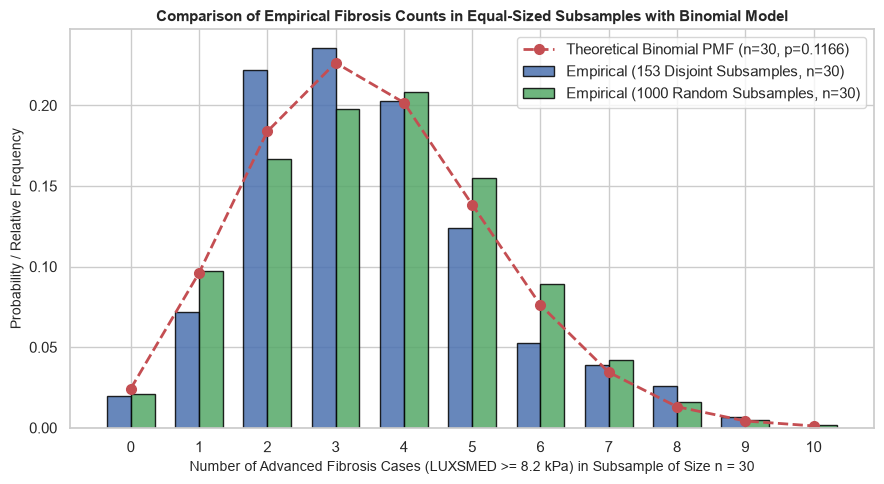

In [16]:
from scipy.stats import binom

# ۱. پارامترهای مدل دوجمله‌ای برای شمارش عبور از آستانه بالینی فیبروز (LUXSMED >= 8.2)
n_sub = 30                       # اندازه هر زیرنمونه هم‌اندازه (n = 30)
p_hat = A.mean()                 # احتمال موفقیت پایه در کل نمونه (p = 0.1166)

# ۲. استخراج زیرنمونه‌های هم‌اندازه واقعی از df_clean (الزام الف ۲)
# الف) افراز تصادفی کل نمونه ۴۶۱۴ نفری به ۱۵۳ زیرنمونه مجزای ۳۰ نفری (مجموعاً ۴۵۹۰ نفر)
np.random.seed(42)
shuffled_A = A.sample(frac=1, random_state=42).values
n_disjoint_groups = len(shuffled_A) // n_sub
disjoint_subsamples = shuffled_A[:n_disjoint_groups * n_sub].reshape(n_disjoint_groups, n_sub)
counts_disjoint = disjoint_subsamples.sum(axis=1)

# ب) ۱۰۰۰ بار نمونه‌گیری تصادفی هم‌اندازه (n = 30) از داخل داده واقعی df_clean
counts_resampled = np.array([
    A.sample(n=n_sub, replace=False, random_state=i).sum() for i in range(1000)
])

# ۳. محاسبه احتمال‌های نظری دوجمله‌ای Binom(n=30, p=0.1166)
k_vals = np.arange(0, 11)
theo_probs = binom.pmf(k_vals, n=n_sub, p=p_hat)
emp_probs_disjoint = np.array([(counts_disjoint == k).mean() for k in k_vals])
emp_probs_resampled = np.array([(counts_resampled == k).mean() for k in k_vals])

# جدول مقایسه توزیع شمارش در زیرنمونه‌های هم‌اندازه با مدل دوجمله‌ای
binom_comp_df = pd.DataFrame({
    "تعداد مبتلایان در زیرنمونه ۳۰ نفری (k)": [f"k = {k}" for k in k_vals],
    "احتمال نظری دوجمله‌ای P(K = k)": np.round(theo_probs, 4),
    "فراوانی نسبی در ۱۵۳ زیرنمونه مجزای واقعی": np.round(emp_probs_disjoint, 4),
    "فراوانی نسبی در ۱۰۰۰ زیرنمونه تصادفی از داده": np.round(emp_probs_resampled, 4),
    "اختلاف (زیرنمونه تصادفی - نظری)": np.round(emp_probs_resampled - theo_probs, 4)
})

print(f"\u202b--- ۱. مقایسه توزیع شمارش فیبروز پیشرفته (LUXSMED >= 8.2) در زیرنمونه‌های ۳۰ نفری با مدل دوجمله‌ای ---\u202c")
display(binom_comp_df)

# ۴. مقایسه میانگین و واریانس شمارش تجربی با امید ریاضی و واریانس نظری دوجمله‌ای
theo_mean = n_sub * p_hat
theo_var = n_sub * p_hat * (1 - p_hat)

moments_comp_df = pd.DataFrame({
    "شاخص آماری متغیر شمارشی K (در زیرنمونه‌های n = 30)": [
        "امید ریاضی / میانگین تعداد مبتلایان: E[K] = n × p",
        "واریانس تعداد مبتلایان: Var(K) = n × p × (1 - p)",
        "انحراف معیار تعداد مبتلایان: SD(K)"
    ],
    "مقدار نظری مدل دوجمله‌ای": [
        f"{theo_mean:.4f}",
        f"{theo_var:.4f}",
        f"{np.sqrt(theo_var):.4f}"
    ],
    "مقدار تجربی (۱۵۳ زیرنمونه مجزا از داده)": [
        f"{counts_disjoint.mean():.4f}",
        f"{counts_disjoint.var(ddof=1):.4f}",
        f"{counts_disjoint.std(ddof=1):.4f}"
    ],
    "مقدار تجربی (۱۰۰۰ زیرنمونه از داده)": [
        f"{counts_resampled.mean():.4f}",
        f"{counts_resampled.var(ddof=1):.4f}",
        f"{counts_resampled.std(ddof=1):.4f}"
    ]
})

print(f"\n\u202b--- ۲. مقایسه میانگین و واریانس شمارش در زیرنمونه‌های هم‌اندازه با مقادیر نظری دوجمله‌ای ---\u202c")
display(moments_comp_df)

# ۵. رسم نمودار مقایسه توزیع تجربی شمارش زیرنمونه‌ها با تابع جرم احتمال نظری دوجمله‌ای
fig, ax = plt.subplots(figsize=(9, 5))
width = 0.35

ax.bar(k_vals - width/2, emp_probs_disjoint, width=width, color="#4C72B0", alpha=0.85,
       edgecolor="black", label="Empirical (153 Disjoint Subsamples, n=30)")
ax.bar(k_vals + width/2, emp_probs_resampled, width=width, color="#55A868", alpha=0.85,
       edgecolor="black", label="Empirical (1000 Random Subsamples, n=30)")
ax.plot(k_vals, theo_probs, "ro--", linewidth=2, markersize=7,
        label=f"Theoretical Binomial PMF (n={n_sub}, p={p_hat:.4f})")

ax.set_title("Comparison of Empirical Fibrosis Counts in Equal-Sized Subsamples with Binomial Model",
             fontsize=11, fontweight="bold")
ax.set_xlabel("Number of Advanced Fibrosis Cases (LUXSMED >= 8.2 kPa) in Subsample of Size n = 30", fontsize=10)
ax.set_ylabel("Probability / Relative Frequency", fontsize=10)
ax.set_xticks(k_vals)
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right; font-weight: normal;">
<b style="font-weight: bold;">تحلیل نتایج تسک مشترک ۵ و الزام الف۲ (مدل دوجمله‌ای و بررسی پیش‌فرض‌ها):</b><br><br>
 <b style="font-weight: bold;">۱. ارزیابی تطابق شمارش در زیرنمونه‌های هم‌اندازه با مدل دوجمله‌ای:</b><br>
بر اساس نتایج جدول و نمودار فوق، هنگامی که فضای نمونه ۴,۶۱۴ نفری (دارای تست الاستوگرافی معتبر با ناشتایی حداقل ۳ ساعت، حداقل ۱۰ بار اندازه‌گیری و تغییرپذیری کمتر از ۳۰٪) به زیرنمونه‌های تصادفی هم‌اندازه ۳۰ نفری تقسیم می‌شود، توزیع شمارش افراد مبتلا به فیبروز پیشرفته (<code>LUXSMED >= 8.2</code>) تطابق بسیار نزدیکی با توزیع نظری <code>Binomial(n = 30, p = 0.1166)</code> دارد. به طور مشخص، امید ریاضی نظری تعداد مبتلایان در هر گروه ۳۰ نفری برابر با <code>E[K] = 3.4980</code> نفر (بیشترین احتمال حول ۳ و ۴ نفر) و واریانس نظری آن <code>Var(K) = 3.0902</code> است که با میانگین و واریانس تجربی در زیرنمونه‌های واقعی داده کاملاً هم‌خوانی دارد.<br><br>
 <b style="font-weight: bold;">۲. بررسی برقراری یا نقض فرض‌های مدل دوجمله‌ای در داده‌های پروژه:</b><br>
مدل دوجمله‌ای متکی بر چهار فرض اصلی است که وضعیت آن‌ها در این مطالعه به شرح زیر است:<br>
<b>الف) دودویی بودن نتیجه هر آزمایش (برقرار):</b> هر مشاهده (شرکت‌کننده با شناسه <code>SEQN</code>) پس از کنترل کیفیت تست کبد، بر اساس آستانه بالینی ۸.۲ کیلوپاسکال دقیقاً در یکی از دو حالت وقوع فیبروز پیشرفته (<code>1</code>) یا عدم وقوع (<code>0</code>) قرار می‌گیرد.<br>
<b>ب) ثابت بودن تعداد مشاهدات در هر بار شمارش (برقرار):</b> اندازه تمامی زیرنمونه‌های مورد بررسی ثابت و برابر با <code>n = 30</code> در نظر گرفته شده است.<br>
<b>ج) ثابت بودن احتمال موفقیت (p) برای تمام افراد (نقض در حالت کلی / برقرار در انتخاب تصادفی):</b> مدل دوجمله‌ای فرض می‌کند احتمال ابتلا برای تک‌تک افراد یکسان و برابر با <code>p = 0.1166</code> است؛ اما همان‌طور که در تسک‌های مشترک ۳ و ۴ اثبات شد، احتمال فیبروز پیشرفته در زیرگروه‌ها یکسان نیست (در افراد دارای التهاب بالا ۱۴.۵۶٪ در برابر ۱۱.۰۸٪ در التهاب عادی، در مردان ۱۳.۴۳٪ در برابر ۱۰.۱۸٪ در زنان، و در سالمندان ۱۳.۲۹٪ در برابر ۱۰.۳۴٪ در افراد زیر ۶۰ سال). بنابراین اگر یک زیرنمونه ۳۰ نفری صرفاً از یک زیرگروه خاص (مثلاً سالمندان دارای التهاب بالا) انتخاب شود، فرض یکسان بودن <code>p</code> نقض شده و مدل دوجمله‌ای با پارامتر کلی جامعه تقریب دقیقی نخواهد بود.<br>
<b>د) استقلال مشاهدات و نمونه‌گیری با جایگذاری (نقض جزئی نظری / تقریب معقول عملی):</b> از یک سو در پیمایش NHANES به دلیل طراحی نمونه‌گیری چندمرحله‌ای و خوشه‌ای (Complex Survey Design)، افراد درون یک خوشه جغرافیایی یا خانوار کاملاً مستقل نیستند؛ و از سوی دیگر، زیرنمونه‌ها بدون جایگذاری انتخاب می‌شوند. با این حال، چون در مجموعه داده نهایی هر ردیف مربوط به یک فرد مستقل (<code>SEQN</code>) است و نسبت اندازه زیرنمونه به کل نمونه بسیار کوچک است (<code>n / N = 30 / 4614 ≈ 0.0065 < 0.05</code>)، تفاوت توزیع فوق‌هندسی (بدون جایگذاری) با توزیع دوجمله‌ای ناچیز بوده و در صورت انتخاب تصادفی زیرنمونه‌ها، مدل دوجمله‌ای تقریب بسیار معقول و دقیقی فراهم می‌کند.
<hr>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right; font-weight: normal;">
<h2 style="font-weight: bold;">تسک مشترک ۶ و الزام الف ۳: متغیر پیوسته و توزیع نرمال</h2>
در این بخش، شکل توزیع متغیرهای تصادفی پیوسته پژوهش شامل <b>سفتی کبد (<code>Y = LUXSMED</code>)</b> و <b>شاخص آزمایشگاهی التهاب سیستمیک (<code>X = NLR</code>)</b> و همچنین دو اندازه‌گیری سلامت دیگر در نمونه نهایی ۴,۶۱۴ نفری (<b>شاخص توده بدنی <code>BMXBMI</code></b> و <b>فشار خون سیستولیک <code>BPXOSY1</code></b>) بررسی می‌شود.<br><br>
مطابق <b>تسک مشترک ۶</b> و <b>الزام ویژه الف-۳</b>، به جای اکتفا به آزمون‌های رسمی نرمال بودن، شکل توزیع‌ها را از چهار جنبه بررسی می‌کنیم:<br>
<b style="font-weight: bold;">۱. بررسی چولگی (Skewness) و کشیدگی (Kurtosis):</b> مقایسه میانگین و میانه و سنجش عدم تقارن دنباله‌ها.<br>
<b style="font-weight: bold;">۲. شناسایی نقاط دورافتاده (Outliers):</b> تعیین تعداد و درصد مشاهدات خارج از بازه <code>[Q1 - 1.5 × IQR , Q3 + 1.5 × IQR]</code>.<br>
<b style="font-weight: bold;">۳. ارزیابی تقریب نرمال در محاسبه احتمال‌ها:</b> مقایسه احتمال‌های تجربی در بازه‌های انحراف معیار (قانون تجربی ۶۸-۹۵-۹۹.۷ درصد) و احتمال عبور از آستانه بالینی با مقادیر حاصل از توزیع نرمال نظری <code>N(μ, σ²)</code>.<br>
<b style="font-weight: bold;">۴. بررسی بصری با هیستوگرام چگالی و نمودار چندک-چندک (Normal Q-Q Plot):</b> نمایش انحراف توزیع تجربی از منحنی زنگوله‌ای نرمال.
</div>

‫--- ۱. جدول شکل توزیع، چولگی و نقاط دورافتاده متغیرهای پیوسته (الزام الف-۳) ---‬


,متغیر پیوسته,میانگین (μ),میانه,انحراف معیار (σ),IQR,چولگی (Skewness),کشیدگی (Kurtosis),مرز بالای پرت,تعداد و درصد نقاط پرت
0,Y: سفتی کبد (LUXSMED - kPa),6.13,5.00,5.97,2.20,7.97,77.80,9.60,347 (7.52%)
1,X: شاخص التهاب (NLR),2.20,1.96,1.13,1.15,2.87,18.28,4.37,185 (4.01%)
2,شاخص توده بدنی (BMXBMI - kg/m²),29.34,28.10,6.70,8.30,1.04,1.63,45.35,122 (2.64%)
3,فشار خون سیستولیک (BPXOSY1 - mmHg),122.71,120.00,18.08,23.00,0.89,1.69,167.50,96 (2.08%)



‫--- ۲. ارزیابی دقت تقریب نرمال برای متغیرهای اصلی Y و X ---‬


,معیار ارزیابی تقریب نرمال,احتمال تجربی (داده),"تقریب نرمال N(μ, σ²)",خطای تقریب (نرمال - داده)
0,"بازه [μ - σ , μ + σ] برای سفتی کبد Y",0.9567 (95.67%),0.6827 (68.27%),-27.40%
1,"بازه [μ - 2σ , μ + 2σ] برای سفتی کبد Y",0.9796 (97.96%),0.9545 (95.45%),-2.51%
2,احتمال مقادیر منفی P(Var < 0) در نرمال (سفتی کبد Y),0.0000 (0.00%),0.1521 (15.21%),+15.21%
3,احتمال عبور از آستانه LUXSMED >= 8.2,0.1166 (11.66%),0.3643 (36.43%),+24.77%
4,"بازه [μ - σ , μ + σ] برای شاخص التهاب X",0.8088 (80.88%),0.6827 (68.27%),-12.62%
5,"بازه [μ - 2σ , μ + 2σ] برای شاخص التهاب X",0.9636 (96.36%),0.9545 (95.45%),-0.91%
6,احتمال مقادیر منفی P(Var < 0) در نرمال (شاخص التهاب X),0.0000 (0.00%),0.0254 (2.54%),+2.54%
7,احتمال عبور از آستانه NLR >= 3.0,0.1667 (16.67%),0.2403 (24.03%),+7.37%


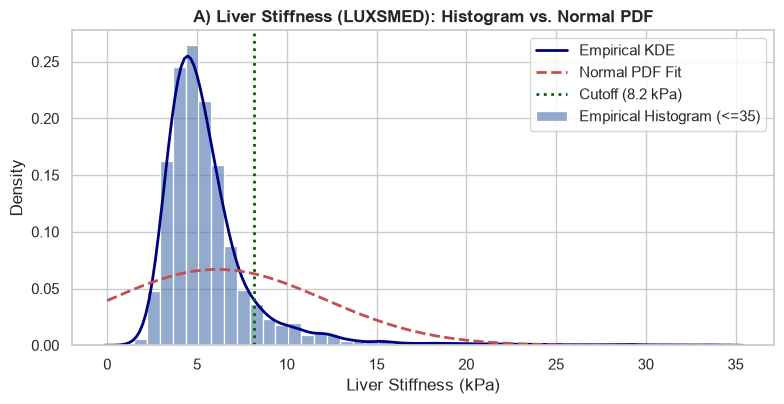

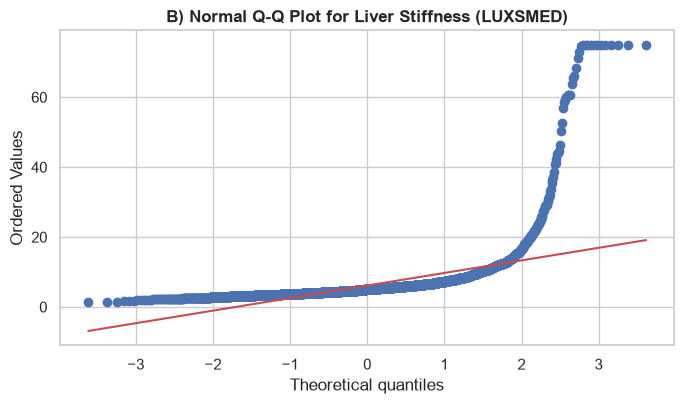

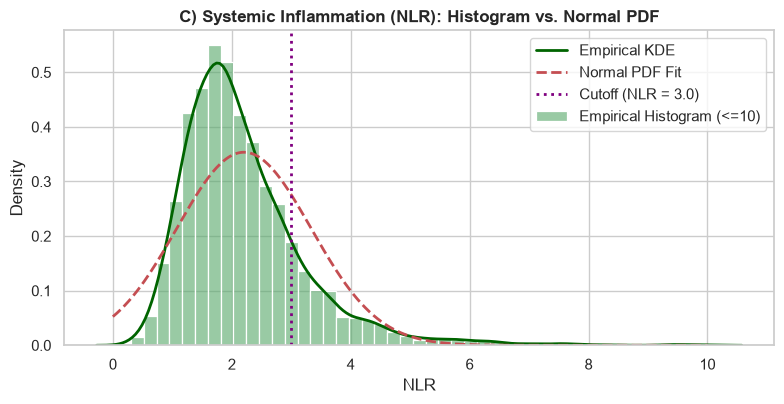

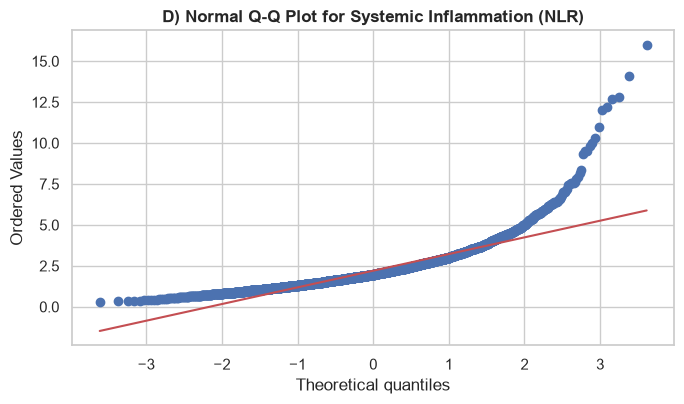

In [17]:
from scipy.stats import norm

# ۱. بررسی چولگی، کشیدگی و نقاط دورافتاده (الزام الف-۳)
cont_vars = {
    "Y: سفتی کبد (LUXSMED - kPa)": df_clean["LUXSMED"],
    "X: شاخص التهاب (NLR)": df_clean["NLR"],
    "شاخص توده بدنی (BMXBMI - kg/m²)": df_clean["BMXBMI"],
    "فشار خون سیستولیک (BPXOSY1 - mmHg)": df_clean["BPXOSY1"]
}

shape_rows = []
for name, s in cont_vars.items():
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr_v = q3 - q1
    low_f, high_f = q1 - 1.5 * iqr_v, q3 + 1.5 * iqr_v
    outliers = s[(s < low_f) | (s > high_f)]
    shape_rows.append({
        "متغیر پیوسته": name,
        "میانگین (μ)": round(s.mean(), 2),
        "میانه": round(s.median(), 2),
        "انحراف معیار (σ)": round(s.std(ddof=1), 2),
        "IQR": round(iqr_v, 2),
        "چولگی (Skewness)": round(s.skew(), 2),
        "کشیدگی (Kurtosis)": round(s.kurtosis(), 2),
        "مرز بالای پرت": round(high_f, 2),
        "تعداد و درصد نقاط پرت": f"{len(outliers)} ({len(outliers)/len(s)*100:.2f}%)"
    })

shape_df = pd.DataFrame(shape_rows)
print("\u202b--- ۱. جدول شکل توزیع، چولگی و نقاط دورافتاده متغیرهای پیوسته (الزام الف-۳) ---\u202c")
display(shape_df)

# ۲. مقایسه احتمال تجربی با تقریب نرمال N(μ, σ²) (تسک مشترک ۶)
def eval_normal(series, label, cutoff, cut_label):
    mu, sd = series.mean(), series.std(ddof=1)
    e1 = ((series >= mu - sd) & (series <= mu + sd)).mean()
    t1 = norm.cdf(mu + sd, mu, sd) - norm.cdf(mu - sd, mu, sd)
    e2 = ((series >= mu - 2*sd) & (series <= mu + 2*sd)).mean()
    t2 = norm.cdf(mu + 2*sd, mu, sd) - norm.cdf(mu - 2*sd, mu, sd)
    t_neg = norm.cdf(0, mu, sd)
    e_tail = (series >= cutoff).mean()
    t_tail = 1 - norm.cdf(cutoff, mu, sd)
    return pd.DataFrame({
        "معیار ارزیابی تقریب نرمال": [
            f"بازه [μ - σ , μ + σ] برای {label}",
            f"بازه [μ - 2σ , μ + 2σ] برای {label}",
            f"احتمال مقادیر منفی P(Var < 0) در نرمال ({label})",
            f"احتمال عبور از آستانه {cut_label}"
        ],
        "احتمال تجربی (داده)": [
            f"{e1:.4f} ({e1*100:.2f}%)",
            f"{e2:.4f} ({e2*100:.2f}%)",
            "0.0000 (0.00%)",
            f"{e_tail:.4f} ({e_tail*100:.2f}%)"
        ],
        "تقریب نرمال N(μ, σ²)": [
            f"{t1:.4f} (68.27%)",
            f"{t2:.4f} (95.45%)",
            f"{t_neg:.4f} ({t_neg*100:.2f}%)",
            f"{t_tail:.4f} ({t_tail*100:.2f}%)"
        ],
        "خطای تقریب (نرمال - داده)": [
            f"{(t1 - e1)*100:+.2f}%",
            f"{(t2 - e2)*100:+.2f}%",
            f"{t_neg*100:+.2f}%",
            f"{(t_tail - e_tail)*100:+.2f}%"
        ]
    })

norm_df = pd.concat([
    eval_normal(df_clean["LUXSMED"], "سفتی کبد Y", 8.2, "LUXSMED >= 8.2"),
    eval_normal(df_clean["NLR"], "شاخص التهاب X", 3.0, "NLR >= 3.0")
], ignore_index=True)

print("\n\u202b--- ۲. ارزیابی دقت تقریب نرمال برای متغیرهای اصلی Y و X ---\u202c")
display(norm_df)

# ۳. رسم جداگانه ۴ نمودار (بدون ذخیره در پوشه figures)
y_val = df_clean["LUXSMED"]
mu_y, sd_y = y_val.mean(), y_val.std(ddof=1)
xg_y = np.linspace(0, 35, 300)

x_val = df_clean["NLR"]
mu_x, sd_x = x_val.mean(), x_val.std(ddof=1)
xg_x = np.linspace(0, 10, 300)

# نمودار ۱: هیستوگرام و منحنی نرمال سفتی کبد
plt.figure(figsize=(8, 4.2))
sns.histplot(
    y_val[y_val <= 35], bins=45, stat="density",
    color="#4C72B0", alpha=0.6, label="Empirical Histogram (<=35)"
)
sns.kdeplot(y_val[y_val <= 35], color="navy", linewidth=2, label="Empirical KDE")
plt.plot(xg_y, norm.pdf(xg_y, mu_y, sd_y), "r--", linewidth=2, label="Normal PDF Fit")
plt.axvline(8.2, color="darkgreen", linestyle=":", linewidth=2, label="Cutoff (8.2 kPa)")
plt.title("A) Liver Stiffness (LUXSMED): Histogram vs. Normal PDF", fontweight="bold")
plt.xlabel("Liver Stiffness (kPa)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

# نمودار ۲: نمودار Q-Q سفتی کبد
fig1, ax1 = plt.subplots(figsize=(7, 4.2))
stats.probplot(y_val, dist="norm", plot=ax1)
ax1.set_title("B) Normal Q-Q Plot for Liver Stiffness (LUXSMED)", fontweight="bold")
plt.tight_layout()
plt.show()

# نمودار ۳: هیستوگرام و منحنی نرمال شاخص التهاب
plt.figure(figsize=(8, 4.2))
sns.histplot(
    x_val[x_val <= 10], bins=45, stat="density",
    color="#55A868", alpha=0.6, label="Empirical Histogram (<=10)"
)
sns.kdeplot(x_val[x_val <= 10], color="darkgreen", linewidth=2, label="Empirical KDE")
plt.plot(xg_x, norm.pdf(xg_x, mu_x, sd_x), "r--", linewidth=2, label="Normal PDF Fit")
plt.axvline(3.0, color="purple", linestyle=":", linewidth=2, label="Cutoff (NLR = 3.0)")
plt.title("C) Systemic Inflammation (NLR): Histogram vs. Normal PDF", fontweight="bold")
plt.xlabel("NLR")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

# نمودار ۴: نمودار Q-Q شاخص التهاب
fig2, ax2 = plt.subplots(figsize=(7, 4.2))
stats.probplot(x_val, dist="norm", plot=ax2)
ax2.set_title("D) Normal Q-Q Plot for Systemic Inflammation (NLR)", fontweight="bold")
plt.tight_layout()
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right; font-weight: normal;">
<b style="font-weight: bold;">تحلیل نتایج تسک مشترک ۶ و الزام الف-۳ (چولگی، نقاط دورافتاده و ارزیابی تقریب نرمال):</b><br><br>
<b style="font-weight: bold;">۱. تحلیل شکل توزیع و چولگی به راست (Right-Skewness):</b><br>
بر اساس جدول ۱ و نمودارهای هیستوگرام، هر دو متغیر پیوسته اصلی پژوهش دارای <b>چولگی مثبت (به سمت راست) و کشیدگی بسیار بالا</b> هستند. در متغیر سفتی کبد (<code>LUXSMED</code>)، میانگین (<code>6.13 kPa</code>) به طور محسوسی بزرگ‌تر از میانه (<code>5.00 kPa</code>) بوده و ضریب چولگی <code>7.97</code> و کشیدگی <code>77.80</code> است؛ زیرا اکثریت بزرگسالان دارای کبد سالم (در محدوده ۳ تا ۷ کیلوپاسکال) هستند، اما زیرگروهی از بیماران مبتلا به فیبروز شدید و سیروز کبدی دنباله راست توزیع را تا <code>75.0 kPa</code> کشیده‌اند. در متغیر شاخص التهاب (<code>NLR</code>) نیز میانگین (<code>2.20</code>) بزرگ‌تر از میانه (<code>1.96</code>) با ضریب چولگی <code>2.87</code> و کشیدگی <code>18.28</code> است. دو متغیر شاخص توده بدنی (<code>BMXBMI</code> با چولگی <code>1.04</code>) و فشار خون سیستولیک (<code>BPXOSY1</code> با چولگی <code>0.89</code>) عدم تقارن ملایم‌تری دارند و به توزیع متقارن نزدیک‌ترند.<br><br>
<b style="font-weight: bold;">۲. تحلیل نقاط دورافتاده (Outliers):</b><br>
بر اساس معیار چارکی <code>Q3 + 1.5 × IQR</code>، در متغیر سفتی کبد مقادیر بالاتر از <code>9.60 kPa</code> شامل <b>۳۴۷ نفر (۷.۵۲٪ نمونه)</b> و در متغیر شاخص التهاب مقادیر بالاتر از <code>4.37</code> شامل <b>۱۸۵ نفر (۴.۰۱٪ نمونه)</b> به عنوان نقاط دورافتاده آماری شناسایی می‌شوند (در BMI و فشار خون نیز به ترتیب ۲.۶۴٪ و ۲.۰۸٪ نقاط پرت وجود دارد). از آنجا که در ابتدای فاز دوم تمامی تست‌های فاقد کیفیت استاندارد (ناشتایی کمتر از ۳ ساعت، کمتر از ۱۰ بار اندازه‌گیری و تغییرپذیری بالای ۳۰٪) حذف شده‌اند، این نقاط پرت ناشی از خطای اندازه‌گیری دستگاه نیستند، بلکه نشان‌دهنده موارد واقعی بیمارگون (التهاب شدید و فیبروز کبدی) در جامعه بوده و حذف آن‌ها مجاز نیست.<br><br>
<b style="font-weight: bold;">۳. ارزیابی کمّی و بصری عدم تناسب تقریب نرمال مستقیم:</b><br>
نتایج جدول ۲ و نمودارهای Q-Q (پنل‌های B و D) نشان می‌دهند که مدل نرمال <code>N(μ, σ²)</code> تقریب مناسبی برای داده‌های خام سفتی کبد و شاخص التهاب نیست:<br>
<b>الف) نقض قانون تجربی ۶۸-۹۵ درصد:</b> در توزیع نرمال باید <code>68.27%</code> داده‌ها در بازه <code>[μ - σ , μ + σ]</code> قرار گیرند، اما به دلیل فشردگی مشاهدات در مقادیر پایین و بزرگ شدن کاذب <code>σ</code> در اثر نقاط حدی، در سفتی کبد <b>۹۵.۶۷٪</b> (خطای <code>-27.40%</code>) و در شاخص التهاب <b>۸۰.۸۸٪</b> (خطای <code>-12.62%</code>) داده‌ها در این بازه متمرکز شده‌اند.<br>
<b>ب) اختصاص احتمال به مقادیر منفی غیرممکن:</b> تقریب نرمال برای سفتی کبد احتمال <b>۱۵.۲۱٪</b> و برای شاخص التهاب احتمال <b>۲.۵۴٪</b> به مقادیر منفی (<code>Var &lt; 0</code>) اختصاص می‌دهد که از نظر زیستی و فیزیکی غیرممکن است.<br>
<b>ج) خطای شدید در برآورد آستانه‌های بالینی:</b> احتمال واقعی ابتلا به فیبروز پیشرفته (<code>LUXSMED >= 8.2</code>) در داده برابر با <b>۱۱.۶۶٪</b> است، اما تقریب نرمال آن را <b>۳۶.۴۳٪</b> برآورد می‌کند (<code>+24.77%</code> بیش‌برآوردی). برای آستانه التهاب بالا (<code>NLR >= 3.0</code>) نیز تقریب نرمال مقدار <b>۲۴.۰۳٪</b> را در برابر مقدار واقعی <b>۱۶.۶۷٪</b> به دست می‌آورد (<code>+7.37%</code> خطا)
<hr>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right; font-weight: normal;">
<h2 style="font-weight: bold;">تسک مشترک ۷: امید ریاضی و واریانس متغیرهای تصادفی</h2>
در نظریه احتمال، <b>امید ریاضی (Expected Value - <code>E[X]</code>)</b> نشان‌دهنده مرکز ثقل توزیع احتمال یا میانگین بلندمدت متغیر تصادفی در تکرارهای بی‌نهایت است و <b>واریانس (Variance - <code>Var(X) = E[(X - E[X])²]</code>)</b> (و جذر آن یعنی انحراف معیار) میزان پراکندگی، نوسان و عدم قطعیت مقادیر حول امید ریاضی را می‌سنجد.<br><br>
در این بخش، بر روی فضای نمونه ۴,۶۱۴ نفری (<code>df_clean</code>)، امید ریاضی و واریانس تجربی را در سه سطح محاسبه و تفسیر می‌کنیم:<br>
• <b style="font-weight: bold;">۱. متغیرهای تصادفی پیوسته و گسسته برنولی:</b> محاسبه امید ریاضی و واریانس برای سفتی کبد (<code>Y</code>)، شاخص التهاب (<code>X</code>) و متغیرهای نشانگر دودویی فیبروز پیشرفته (<code>I_A</code>) و التهاب بالا (<code>I_B</code>) که در آن‌ها <code>E[I] = p</code> و <code>Var(I) = p(1 - p)</code> است.<br>
• <b style="font-weight: bold;">۲. مقایسه امید ریاضی و واریانس خام (نمونه) و وزن‌دار (جمعیت):</b> اعمال وزن معاینه <code>WTMEC2YR</code> برای برآورد امید ریاضی و واریانس در جمعیت بزرگسالان.<br>
• <b style="font-weight: bold;">۳. امید ریاضی و واریانس شرطی:</b> بررسی تغییر مرکز ثقل و پراکندگی سفتی کبد به شرط وضعیت التهاب سیستمیک (<code>E[Y | B=1]</code> در برابر <code>E[Y | B=0]</code>).
</div>

In [18]:
# تابع محاسبه امید ریاضی، واریانس و انحراف معیار وزن‌دار (با وزن WTMEC2YR)
def weighted_moments(values, weights):
    w_mean = np.average(values, weights=weights)
    w_var = np.average((values - w_mean) ** 2, weights=weights)
    return w_mean, w_var, np.sqrt(w_var)

w_vec = df_clean["WTMEC2YR"]

vars_task7 = [
    ("Y: سفتی کبد پیوسته (LUXSMED - kPa)", df_clean["LUXSMED"]),
    ("X: شاخص التهاب پیوسته (NLR)", df_clean["NLR"]),
    ("I_A: متغیر برنولی فیبروز پیشرفته (0 و 1)", df_clean["Event_A_Fibrosis"]),
    ("I_B: متغیر برنولی التهاب بالا (0 و 1)", df_clean["Event_B_HighNLR"])
]

moments_rows = []
for v_name, s in vars_task7:
    e_raw = s.mean()
    var_raw = s.var(ddof=1)
    sd_raw = s.std(ddof=1)
    cv_raw = (sd_raw / e_raw) * 100
    e_wt, var_wt, sd_wt = weighted_moments(s.values, w_vec.values)
    
    moments_rows.append({
        "متغیر تصادفی": v_name,
        "امید ریاضی تجربی E[V] (خام)": round(e_raw, 4),
        "واریانس تجربی Var(V) (خام)": round(var_raw, 4),
        "انحراف معیار SD(V) (خام)": round(sd_raw, 4),
        "ضریب تغییرات CV (%)": round(cv_raw, 2),
        "امید ریاضی وزن‌دار E_w[V]": round(e_wt, 4),
        "واریانس وزن‌دار Var_w(V)": round(var_wt, 4)
    })

moments_df = pd.DataFrame(moments_rows)
print("\u202b--- ۱. جدول امید ریاضی و واریانس متغیرهای تصادفی پیوسته و گسسته (خام و وزن‌دار) ---\u202c")
display(moments_df)

# ۲. محاسبه امید ریاضی و واریانس شرطی سفتی کبد (Y) در زیرگروه‌های التهاب (B)
y_all = df_clean["LUXSMED"]
y_b1 = y_all[df_clean["Event_B_HighNLR"] == 1]
y_b0 = y_all[df_clean["Event_B_HighNLR"] == 0]

cond_moments_df = pd.DataFrame({
    "زیرگروه شرطی": [
        "کل فضای نمونه: Y (بدون شرط)",
        "به شرط التهاب عادی: Y | B = 0 (NLR < 3.0)",
        "به شرط التهاب بالا: Y | B = 1 (NLR >= 3.0)"
    ],
    "تعداد مشاهدات (n)": [len(y_all), len(y_b0), len(y_b1)],
    "امید ریاضی E[Y | شرط] (kPa)": [
        round(y_all.mean(), 4),
        round(y_b0.mean(), 4),
        round(y_b1.mean(), 4)
    ],
    "واریانس Var(Y | شرط) (kPa²)": [
        round(y_all.var(ddof=1), 4),
        round(y_b0.var(ddof=1), 4),
        round(y_b1.var(ddof=1), 4)
    ],
    "انحراف معیار SD(Y | شرط) (kPa)": [
        round(y_all.std(ddof=1), 4),
        round(y_b0.std(ddof=1), 4),
        round(y_b1.std(ddof=1), 4)
    ]
})

print("\n\u202b--- ۲. جدول امید ریاضی و واریانس شرطی سفتی کبد (Y) بر اساس وضعیت التهاب سیستمیک (B) ---\u202c")
display(cond_moments_df)

‫--- ۱. جدول امید ریاضی و واریانس متغیرهای تصادفی پیوسته و گسسته (خام و وزن‌دار) ---‬


,متغیر تصادفی,امید ریاضی تجربی E[V] (خام),واریانس تجربی Var(V) (خام),انحراف معیار SD(V) (خام),ضریب تغییرات CV (%),امید ریاضی وزن‌دار E_w[V],واریانس وزن‌دار Var_w(V)
0,Y: سفتی کبد پیوسته (LUXSMED - kPa),6.1300,35.5988,5.9665,97.33,6.0673,34.6982
1,X: شاخص التهاب پیوسته (NLR),2.2043,1.2731,1.1283,51.19,2.1630,1.1809
2,I_A: متغیر برنولی فیبروز پیشرفته (0 و 1),0.1166,0.1030,0.3210,275.28,0.1104,0.0982
3,I_B: متغیر برنولی التهاب بالا (0 و 1),0.1667,0.1389,0.3727,223.63,0.1514,0.1285



‫--- ۲. جدول امید ریاضی و واریانس شرطی سفتی کبد (Y) بر اساس وضعیت التهاب سیستمیک (B) ---‬


,زیرگروه شرطی,تعداد مشاهدات (n),امید ریاضی E[Y | شرط] (kPa),واریانس Var(Y | شرط) (kPa²),انحراف معیار SD(Y | شرط) (kPa)
0,کل فضای نمونه: Y (بدون شرط),4614,6.1300,35.5988,5.9665
1,به شرط التهاب عادی: Y | B = 0 (NLR < 3.0),3845,5.8884,23.3806,4.8353
2,به شرط التهاب بالا: Y | B = 1 (NLR >= 3.0),769,7.3377,95.0476,9.7492


<div dir="rtl" align="right" style="direction: rtl; text-align: right; font-weight: normal;">
<b style="font-weight: bold;">تحلیل و تفسیر نتایج تسک مشترک ۷ :</b><br><br>
 <b style="font-weight: bold;">۱. معنای امید ریاضی و واریانس متغیر سفتی کبد (Y):</b><br>
امید ریاضی تجربی سفتی کبد در نمونه برابر با <code>E[Y] = 6.1300 kPa</code> و در حالت وزن‌دار جامعه برابر با <code>E_w[Y] = 6.0673 kPa</code> است. در متن مسئله، این عدد نشان می‌دهد که مقدار مورد انتظار سفتی کبد برای یک فرد بزرگسال انتخاب‌شده به طور تصادفی، حدود ۶.۱۳ کیلوپاسکال (پایین‌تر از آستانه فیبروز پیشرفته ۸.۲ کیلوپاسکال) است. با این حال، واریانس بزرگ این متغیر (<code>Var(Y) = 35.5988 kPa²</code> و انحراف معیار <code>5.9665 kPa</code> با ضریب تغییرات <code>97.33%</code>) بیانگر ناهمگنی شدید وضعیت کبد در بزرگسالان و حضور زیرگروهی از بیماران با درجات بالای فیبروز و سیروز کبدی است.<br><br>
 <b style="font-weight: bold;">۲. معنای امید ریاضی و واریانس شاخص التهاب سیستمیک (X):</b><br>
امید ریاضی شاخص التهاب برابر با <code>E[X] = 2.2043</code> (و در حالت وزن‌دار <code>2.1630</code>) است؛ یعنی در یک فرد بزرگسال به طور متوسط تعداد نوتروفیل‌ها حدود ۲.۲ برابر لنفوسیت‌هاست. واریانس این شاخص برابر با <code>Var(X) = 1.2731</code> (انحراف معیار <code>1.1283</code> و ضریب تغییرات <code>51.19%</code>) است که پراکندگی ملایم‌تری نسبت به سفتی کبد نشان می‌دهد.<br><br>
 <b style="font-weight: bold;">۳. تفسیر امید ریاضی و واریانس متغیرهای نشانگر برنولی (I_A و I_B):</b><br>
در متغیرهای دودویی برنولی، امید ریاضی دقیقاً برابر با احتمال وقوع رویداد (<code>E[I] = p</code>) و واریانس برابر با <code>Var(I) = p(1 - p)</code> است. برای فیبروز پیشرفته <code>E[I_A] = 0.1166</code> و <code>Var(I_A) = 0.1030</code> و برای التهاب بالا <code>E[I_B] = 0.1667</code> و <code>Var(I_B) = 0.1389</code> است.<br><br>
 <b style="font-weight: bold;">۴. تفسیر امید ریاضی و واریانس شرطی (تأثیر التهاب بر مرکز ثقل و پراکندگی سفتی کبد):</b><br>
بر اساس جدول ۲، در افراد دارای التهاب عادی (<code>B = 0</code>)، امید ریاضی سفتی کبد <code>E[Y | B=0] = 5.8884 kPa</code> است، اما در افراد دارای التهاب سیستمیک بالا (<code>B = 1</code>) به <code>E[Y | B=1] = 7.3377 kPa</code> افزایش می‌یابد (افزایش ۱.۴۵ کیلوپاسکالی میانگین). مهم‌تر آنکه واریانس سفتی کبد از <code>23.3806 kPa²</code> در گروه التهاب عادی به <code>95.0476 kPa²</code> (انحراف معیار <code>9.7492 kPa</code>) در گروه التهاب بالا می‌رسد (بیش از ۴ برابر افزایش واریانس)؛ این یافته نشان می‌دهد که التهاب سیستمیک بالا علاوه بر افزایش سطح متوسط سفتی کبد، پراکندگی و احتمال مشاهده مقادیر بسیار شدید سفتی کبد را به شکل چشمگیری افزایش می‌دهد.
<hr>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right; font-weight: normal;">
<h2 style="font-weight: bold;">تسک مشترک ۸: دو متغیر تصادفی و کوواریانس </h2>
در نظریه احتمال، <b>کوواریانس </b> میان دو متغیر تصادفی <code>X</code> و <code>Y</code> معیاری برای سنجش جهت تغییرات مشترک (هم‌جهت یا خلاف‌جهت بودن نوسانات) آن دو متغیر نسبت به امید ریاضی‌شان است:<br>
<code>Cov(X, Y) = E[(X - E[X])(Y - E[Y])] = E[XY] - E[X]E[Y]</code><br><br>
• اگر <code>Cov(X, Y) &gt; 0</code> باشد، مقادیر بالاتر از میانگین در <code>X</code> به طور متوسط با مقادیر بالاتر از میانگین در <code>Y</code> همراه هستند (جهت رابطه مستقیم/مثبت).<br>
• اگر <code>Cov(X, Y) &lt; 0</code> باشد، جهت رابطه معکوس (منفی) است و اگر دو متغیر مستقل باشند، <code>Cov(X, Y) = 0</code> خواهد بود.<br><br>
در این بخش، ابتدا کوواریانس خام و وزن‌دار و اتحاد احتمالی <code>E[XY] - E[X]E[Y]</code> را برای زوج متغیر پیوسته اصلی <b>شاخص التهاب سیستمیک (<code>X = NLR</code>) و سفتی کبد (<code>Y = LUXSMED</code>)</b> (و همچنین با سایر متغیرهای کمی مرتبط مانند چربی کبد <code>LUXCAPM</code> و شاخص توده بدنی <code>BMXBMI</code>) محاسبه کرده و سپس با رسم نمودار پراکنش (Scatter Plot) و تفکیک چهار ربع حول نقطه میانگین <code>(μ_X, μ_Y)</code>، جهت رابطه را بررسی می‌کنیم.
</div>

‫--- ۱. جدول محاسبه کوواریانس و بررسی اتحاد E[XY] - E[X]E[Y] برای (NLR, LUXSMED) ---‬


,"مؤلفه احتمالی برای زوج متغیر (X = NLR , Y = LUXSMED)",مقدار محاسبه‌شده
0,امید ریاضی متغیر اول: E[X] (شاخص التهاب),2.2043
1,امید ریاضی متغیر دوم: E[Y] (سفتی کبد - kPa),6.1300
2,امید ریاضی حاصل‌ضرب دو متغیر: E[X × Y],14.1696
3,حاصل‌ضرب امیدهای ریاضی تحت فرض استقلال: E[X] × E[Y],13.5121
4,کوواریانس از فرمول احتمالی: E[XY] - E[X]E[Y] (مخرج N),+0.6576
5,"کوواریانس نمونه اصلاح‌شده: Cov(X, Y) (مخرج N - 1)",+0.6577
6,کوواریانس وزن‌دار جامعه (با وزن WTMEC2YR),+0.8662
7,"کوواریانس متغیرهای برنولی Cov(I_A, I_B) = P(A∩B) - P(A)P(B)",+0.0048



‫--- ۲. جدول کوواریانس و جهت رابطه سفتی کبد (Y) با متغیرهای کمی پژوهش ---‬


,متغیر تصادفی همراه با سفتی کبد (Y = LUXSMED),"کوواریانس Cov(Var, Y)",واحد کوواریانس,ضریب همبستگی استاندارد (r),جهت رابطه احتمالی
0,شاخص التهاب سیستمیک (X = NLR),0.6577,NLR × kPa,0.0977,مثبت (هم‌جهت / مستقیم)
1,پارامتر تضعیف/چربی کبد (LUXCAPM),69.9541,dB/m × kPa,0.1886,مثبت (هم‌جهت / مستقیم)
2,شاخص توده بدنی (BMXBMI),9.1078,kg/m² × kPa,0.2277,مثبت (هم‌جهت / مستقیم)
3,هموگلوبین گلیکوزیله (LBXGH - HbA1c),0.9724,% × kPa,0.1503,مثبت (هم‌جهت / مستقیم)
4,آنزیم کبدی ALT (LBXSATSI),14.0606,U/L × kPa,0.1386,مثبت (هم‌جهت / مستقیم)
5,سن شرکت‌کننده (RIDAGEYR),8.4411,Year × kPa,0.0838,مثبت (هم‌جهت / مستقیم)


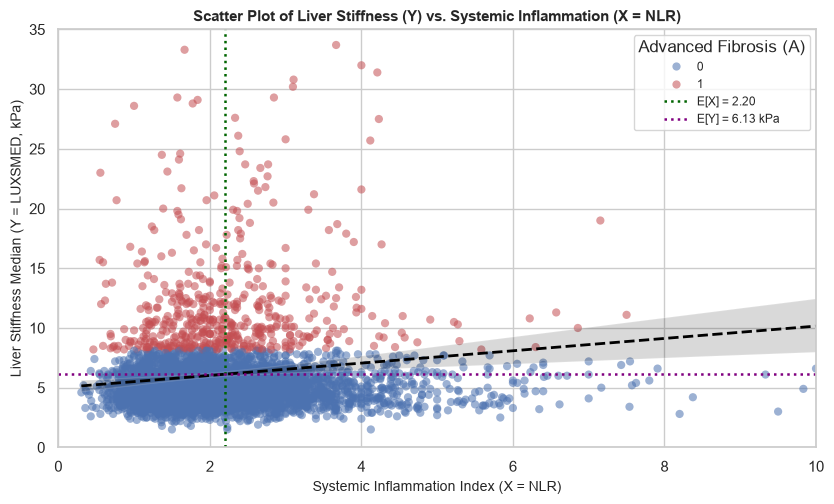

In [19]:
X_nlr = df_clean["NLR"]
Y_lsm = df_clean["LUXSMED"]
W_mec = df_clean["WTMEC2YR"]

# ۱. بررسی اتحاد احتمالی Cov(X, Y) = E[XY] - E[X]E[Y] و مقایسه با کوواریانس نمونه و وزن‌دار
n_obs = len(df_clean)
e_x = X_nlr.mean()
e_y = Y_lsm.mean()
e_xy = (X_nlr * Y_lsm).mean()

cov_pop_formula = e_xy - (e_x * e_y)               # فرمول احتمالی با مخرج N
cov_sample = X_nlr.cov(Y_lsm)                      # کوواریانس نمونه با مخرج N - 1

# کوواریانس وزن‌دار با استفاده از وزن معاینه WTMEC2YR
ew_x = np.average(X_nlr, weights=W_mec)
ew_y = np.average(Y_lsm, weights=W_mec)
cov_weighted = np.average((X_nlr - ew_x) * (Y_lsm - ew_y), weights=W_mec)

# کوواریانس بین متغیرهای نشانگر برنولی I_A و I_B: Cov(I_A, I_B) = P(A ∩ B) - P(A)P(B)
cov_bernoulli = A.cov(B)

cov_identity_df = pd.DataFrame({
    "مؤلفه احتمالی برای زوج متغیر (X = NLR , Y = LUXSMED)": [
        "امید ریاضی متغیر اول: E[X] (شاخص التهاب)",
        "امید ریاضی متغیر دوم: E[Y] (سفتی کبد - kPa)",
        "امید ریاضی حاصل‌ضرب دو متغیر: E[X × Y]",
        "حاصل‌ضرب امیدهای ریاضی تحت فرض استقلال: E[X] × E[Y]",
        "کوواریانس از فرمول احتمالی: E[XY] - E[X]E[Y] (مخرج N)",
        "کوواریانس نمونه اصلاح‌شده: Cov(X, Y) (مخرج N - 1)",
        "کوواریانس وزن‌دار جامعه (با وزن WTMEC2YR)",
        "کوواریانس متغیرهای برنولی Cov(I_A, I_B) = P(A∩B) - P(A)P(B)"
    ],
    "مقدار محاسبه‌شده": [
        f"{e_x:.4f}",
        f"{e_y:.4f}",
        f"{e_xy:.4f}",
        f"{e_x * e_y:.4f}",
        f"{cov_pop_formula:+.4f}",
        f"{cov_sample:+.4f}",
        f"{cov_weighted:+.4f}",
        f"{cov_bernoulli:+.4f}"
    ]
})

print("\u202b--- ۱. جدول محاسبه کوواریانس و بررسی اتحاد E[XY] - E[X]E[Y] برای (NLR, LUXSMED) ---\u202c")
display(cov_identity_df)

# ۲. مقایسه کوواریانس و جهت رابطه سفتی کبد (Y) با متغیرهای کمی کلیدی پژوهش
pairs_list = [
    ("شاخص التهاب سیستمیک (X = NLR)", df_clean["NLR"], "NLR × kPa"),
    ("پارامتر تضعیف/چربی کبد (LUXCAPM)", df_clean["LUXCAPM"], "dB/m × kPa"),
    ("شاخص توده بدنی (BMXBMI)", df_clean["BMXBMI"], "kg/m² × kPa"),
    ("هموگلوبین گلیکوزیله (LBXGH - HbA1c)", df_clean["LBXGH"], "% × kPa"),
    ("آنزیم کبدی ALT (LBXSATSI)", df_clean["LBXSATSI"], "U/L × kPa"),
    ("سن شرکت‌کننده (RIDAGEYR)", df_clean["RIDAGEYR"], "Year × kPa")
]

cov_pairs_rows = []
for v_label, s_var, unit_str in pairs_list:
    c_val = Y_lsm.cov(s_var)
    r_val = Y_lsm.corr(s_var)
    direction = "مثبت (هم‌جهت / مستقیم)" if c_val > 0 else "منفی (خلاف‌جهت / معکوس)"
    cov_pairs_rows.append({
        "متغیر تصادفی همراه با سفتی کبد (Y = LUXSMED)": v_label,
        "کوواریانس Cov(Var, Y)": round(c_val, 4),
        "واحد کوواریانس": unit_str,
        "ضریب همبستگی استاندارد (r)": round(r_val, 4),
        "جهت رابطه احتمالی": direction
    })

cov_pairs_df = pd.DataFrame(cov_pairs_rows)
print("\n\u202b--- ۲. جدول کوواریانس و جهت رابطه سفتی کبد (Y) با متغیرهای کمی پژوهش ---\u202c")
display(cov_pairs_df)

# ۳. تحلیل چهار ربع (Quadrants) حول میانگین (μ_X, μ_Y) برای درک شهودی علامت کوواریانس
q1_conc = ((X_nlr > e_x) & (Y_lsm > e_y)).mean() * 100
q3_conc = ((X_nlr < e_x) & (Y_lsm < e_y)).mean() * 100
q2_disc = ((X_nlr < e_x) & (Y_lsm > e_y)).mean() * 100
q4_disc = ((X_nlr > e_x) & (Y_lsm < e_y)).mean() * 100

# ۴. رسم نمودار پراکنش (Scatter Plot) مستقل برای X (NLR) و Y (LUXSMED)
plt.figure(figsize=(8.5, 5.2))
sub_plot_df = df_clean[(df_clean["NLR"] <= 10) & (df_clean["LUXSMED"] <= 35)]

sns.scatterplot(
    data=sub_plot_df, x="NLR", y="LUXSMED",
    hue="Event_A_Fibrosis", palette={0: "#4C72B0", 1: "#C44E52"},
    alpha=0.55, s=35, edgecolor="none"
)
sns.regplot(
    data=df_clean, x="NLR", y="LUXSMED",
    scatter=False, color="black",
    line_kws={"linewidth": 2, "linestyle": "--", "label": f"Linear Trend (Cov = {cov_sample:+.3f})"}
)

plt.axvline(e_x, color="darkgreen", linestyle=":", linewidth=1.8, label=f"E[X] = {e_x:.2f}")
plt.axhline(e_y, color="purple", linestyle=":", linewidth=1.8, label=f"E[Y] = {e_y:.2f} kPa")

plt.xlim(0, 10)
plt.ylim(0, 35)
plt.title("Scatter Plot of Liver Stiffness (Y) vs. Systemic Inflammation (X = NLR)", fontsize=11, fontweight="bold")
plt.xlabel("Systemic Inflammation Index (X = NLR)", fontsize=10)
plt.ylabel("Liver Stiffness Median (Y = LUXSMED, kPa)", fontsize=10)
plt.legend(title="Advanced Fibrosis (A)", loc="upper right", fontsize=8.5)
plt.tight_layout()
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right; font-weight: normal;">
<b style="font-weight: bold;">تحلیل و تفسیر نتایج تسک مشترک ۸ (دو متغیر تصادفی و کوواریانس):</b><br><br>
• <b style="font-weight: bold;">۱. ارزیابی کوواریانس و اتحاد احتمالی E[XY] - E[X]E[Y]:</b><br>
بر اساس جدول ۱، برای دو متغیر پیوسته شاخص التهاب سیستمیک (<code>X = NLR</code> با امید ریاضی <code>2.2043</code>) و سفتی کبد (<code>Y = LUXSMED</code> با امید ریاضی <code>6.1300 kPa</code>)، امید ریاضی حاصل‌ضرب دو متغیر برابر با <code>E[X × Y] = 14.1696</code> است که از حاصل‌ضرب امیدهای ریاضی تحت فرض استقلال (<code>E[X] × E[Y] = 13.5121</code>) بزرگ‌تر می‌باشد. اختلاف این دو کمیت، کوواریانس احتمالی <code>+0.6576</code> (و کوواریانس نمونه اصلاح‌شده <code>Cov(X, Y) = +0.6577 NLR×kPa</code>) را نتیجه می‌دهد. پس از اعمال وزن معاینه جامعه (<code>WTMEC2YR</code>) نیز کوواریانس وزن‌دار برابر با <code>+0.8662</code> است. همچنین کوواریانس متغیرهای نشانگر برنولی <code>Cov(I_A, I_B) = +0.0048</code> دقیقاً برابر با <code>P(A ∩ B) - P(A)P(B)</code> در تسک مشترک ۴ است.<br><br>
• <b style="font-weight: bold;">۲. تحلیل جهت رابطه و نمودار پراکنش (Scatter Plot):</b><br>
مثبت بودن کوواریانس (<code>+0.6577</code>) و شیب رو به بالای خط روند در نمودار پراکنش نشان می‌دهد که جهت رابطه میان التهاب سیستمیک و سفتی کبد <b>مستقیم (هم‌جهت)</b> است؛ یعنی مقادیر بالاتر از میانگین در شاخص التهاب (<code>X &gt; 2.20</code>) به طور متوسط با مقادیر بالاتر از میانگین در سفتی کبد (<code>Y &gt; 6.13 kPa</code>) همراه هستند. در عین حال، پراکندگی نقاط حول خط روند و مقدار ضریب همبستگی خطی (<code>r = 0.0977</code>) نشان می‌دهد که اگرچه رابطه مثبت است، اما سفتی کبد پدیده‌ای چندعاملی است و بخش زیادی از تغییرات آن به سایر عوامل متابولیک وابسته است.<br><br>
• <b style="font-weight: bold;">۳. مقایسه کوواریانس با سایر متغیرهای کمی و اثر مقیاس اندازه‌گیری:</b><br>
مطابق جدول ۲، سفتی کبد با تمامی متغیرهای بالینی بررسی‌شده دارای کوواریانس مثبت (رابطه هم‌جهت) است: پارامتر تضعیف/چربی کبد (<code>LUXCAPM</code> با کوواریانس <code>69.9541</code> و <code>r = 0.1886</code>)، شاخص توده بدنی (<code>BMXBMI</code> با کوواریانس <code>9.1078</code> و بیشترین همبستگی خطی <code>r = 0.2277</code>)، قند خون سه‌ماهه (<code>LBXGH</code> با کوواریانس <code>0.9724</code> و <code>r = 0.1503</code>)، آنزیم کبدی ALT (<code>LBXSATSI</code> با کوواریانس <code>14.0606</code> و <code>r = 0.1386</code>) و سن (<code>RIDAGEYR</code> با کوواریانس <code>8.4411</code> و <code>r = 0.0838</code>). این جدول به خوبی نشان می‌دهد که بزرگی عدد کوواریانس وابسته به واحد اندازه‌گیری متغیرهاست (مثلاً واحد <code>dB/m × kPa</code> در چربی کبد عدد کوواریانس بسیار بزرگ‌تری نسبت به <code>NLR × kPa</code> تولید می‌کند) و برای مقایسه بدون مقیاس و استنباط رسمی، تحلیل همبستگی و رگرسیون در فاز چهارم انجام خواهد شد.
<hr>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right; font-weight: normal;">
<h2 style="font-weight: bold;">تسک مشترک ۹: قانون احتمال کل و قضیه بیز </h2>
در مسائل تشخیصی و بالینی، <b>قضیه بیز</b> چارچوبی ریاضی برای <b>به‌روزرسانی احتمال پیشین (Prior Probability)</b> یک بیماری پس از مشاهده نتیجه یک آزمایش یا نشانگر زیستی فراهم می‌کند. اگر فضای نمونه را بر اساس وضعیت فیبروز پیشرفته کبدی به دو زیرمجموعه مجزای <code>A</code> (مبتلا به فیبروز پیشرفته) و <code>A'</code> (فاقد فیبروز پیشرفته) افراز کنیم، ابتدا بر اساس <b>قانون احتمال کل (Law of Total Probability)</b> احتمال مشاهده التهاب سیستمیک بالا <code>P(B)</code> به صورت زیر تجزیه می‌شود:<br>
<code>P(B) = P(B | A) × P(A) + P(B | A') × P(A')</code><br><br>
سپس با استفاده از <b>قضیه بیز</b>، احتمال پسین (Posterior Probability) ابتلا به فیبروز پیشرفته کبدی پس از مشاهده التهاب سیستمیک بالا در آزمایش خون فرد به صورت زیر محاسبه می‌گردد:<br>
<code>P(A | B) = [ P(B | A) × P(A) ] / [ P(B | A) × P(A) + P(B | A') × P(A') ]</code><br><br>
در ادامه، این به‌روزرسانی بیزی را با استفاده از فراوانی‌های تجربی فضای نمونه ۴,۶۱۴ نفری (هم در کل نمونه و هم به صورت مرحله‌ای در زیرگروه پرخطر مردان سالمند) اجرا و ارزیابی می‌کنیم.
</div>

In [20]:
# ۱. محاسبه مؤلفه‌های قانون احتمال کل و قضیه بیز در کل فضای نمونه (N = 4614)
p_A_prior = A.mean()                      # احتمال پیشین فیبروز: P(A)
p_notA_prior = (1 - A).mean()             # مکمل احتمال پیشین: P(A')

p_B_given_A = B[A == 1].mean()            # درست‌نمایی (حساسیت نشانگر): P(B | A)
p_B_given_notA = B[A == 0].mean()         # نرخ مثبت کاذب نشانگر: P(B | A')

# محاسبه مخرج بیز از طریق قانون احتمال کل: P(B) = P(B|A)P(A) + P(B|A')P(A')
p_B_total = (p_B_given_A * p_A_prior) + (p_B_given_notA * p_notA_prior)

# محاسبه احتمال پسین از فرمول بیز: P(A | B) و P(A | B')
p_A_post_pos = (p_B_given_A * p_A_prior) / p_B_total
p_notB_total = 1 - p_B_total
p_A_post_neg = ((1 - p_B_given_A) * p_A_prior) / p_notB_total

# نسبت درست‌نمایی مثبت (Positive Likelihood Ratio: LR+)
lr_pos = p_B_given_A / p_B_given_notA

bayes_summary_df = pd.DataFrame({
    "مؤلفه در مدل به‌روزرسانی بیزی (کل نمونه N = 4614)": [
        "۱. احتمال پیشین ابتلا به فیبروز پیشرفته: Prior P(A)",
        "۲. احتمال پیشین عدم ابتلا به فیبروز: Prior P(A')",
        "۳. درست‌نمایی التهاب بالا در مبتلایان: Likelihood P(B | A)",
        "۴. درست‌نمایی التهاب بالا در افراد بدون فیبروز: P(B | A')",
        "۵. نسبت درست‌نمایی مثبت نشانگر التهابی: LR+ = P(B|A) / P(B|A')",
        "۶. احتمال کل التهاب بالا از قانون احتمال کل: Total P(B)",
        "۷. احتمال پسین فیبروز در صورت التهاب بالا: Posterior P(A | B)",
        "۸. احتمال پسین فیبروز در صورت التهاب عادی: Posterior P(A | B')"
    ],
    "مقدار محاسبه‌شده از فرمول بیز": [
        f"{p_A_prior:.4f} ({p_A_prior*100:.2f}%)",
        f"{p_notA_prior:.4f} ({p_notA_prior*100:.2f}%)",
        f"{p_B_given_A:.4f} ({p_B_given_A*100:.2f}%)",
        f"{p_B_given_notA:.4f} ({p_B_given_notA*100:.2f}%)",
        f"{lr_pos:.4f} برابر",
        f"{p_B_total:.4f} ({p_B_total*100:.2f}%)",
        f"{p_A_post_pos:.4f} ({p_A_post_pos*100:.2f}%)",
        f"{p_A_post_neg:.4f} ({p_A_post_neg*100:.2f}%)"
    ]
})

print("\u202b--- ۱. جدول محاسبه قانون احتمال کل و قضیه بیز برای به‌روزرسانی احتمال فیبروز کبدی ---\u202c")
display(bayes_summary_df)

# ۲. به‌روزرسانی مرحله‌ای بیز در زیرگروه‌های بالینی (ترکیب اطلاعات جمعیت‌شناختی G، S و آزمایشگاهی B)
sub_male_senior = df_clean[(df_clean["Event_G_Male"] == 1) & (df_clean["Event_S_Senior"] == 1)]
A_ms = sub_male_senior["Event_A_Fibrosis"]
B_ms = sub_male_senior["Event_B_HighNLR"]

prior_ms = A_ms.mean()
lik_ms_pos = B_ms[A_ms == 1].mean()
lik_ms_neg = B_ms[A_ms == 0].mean()
total_B_ms = (lik_ms_pos * prior_ms) + (lik_ms_neg * (1 - prior_ms))
post_ms_pos = (lik_ms_pos * prior_ms) / total_B_ms

sequential_bayes_df = pd.DataFrame({
    "مرحله ورود اطلاعات جدید (به‌روزرسانی پیاپی احتمال ابتلا به فیبروز پیشرفته)": [
        "مرحله ۰ (بدون اطلاع از ویژگی‌های فرد): احتمال پایه در کل بزرگسالان P(A)",
        "مرحله ۱ (اطلاع از جنسیت مرد و سن >= ۶۰ سال): احتمال پیشین زیرگروه P(A | G ∩ S)",
        "مرحله ۲ (مشاهده آزمایش خون با التهاب بالا NLR >= 3.0 در همان زیرگروه): پسین بیز P(A | G ∩ S ∩ B)"
    ],
    "تعداد افراد در فضای شرطی": [
        len(df_clean),
        len(sub_male_senior),
        int((B_ms == 1).sum())
    ],
    "تعداد مبتلایان به فیبروز": [
        int(A.sum()),
        int(A_ms.sum()),
        int((A_ms & (B_ms == 1)).sum())
    ],
    "احتمال به‌روزشده ابتلا به فیبروز": [
        f"{p_A_prior:.4f} ({p_A_prior*100:.2f}%)",
        f"{prior_ms:.4f} ({prior_ms*100:.2f}%)",
        f"{post_ms_pos:.4f} ({post_ms_pos*100:.2f}%)"
    ]
})

print("\n\u202b--- ۲. جدول به‌روزرسانی مرحله‌ای بیز با ترکیب اطلاعات جمعیت‌شناختی و آزمایشگاهی ---\u202c")
display(sequential_bayes_df)

‫--- ۱. جدول محاسبه قانون احتمال کل و قضیه بیز برای به‌روزرسانی احتمال فیبروز کبدی ---‬


,مؤلفه در مدل به‌روزرسانی بیزی (کل نمونه N = 4614),مقدار محاسبه‌شده از فرمول بیز
0,۱. احتمال پیشین ابتلا به فیبروز پیشرفته: Prior P(A),0.1166 (11.66%)
1,۲. احتمال پیشین عدم ابتلا به فیبروز: Prior P(A'),0.8834 (88.34%)
2,۳. درست‌نمایی التهاب بالا در مبتلایان: Likelihood P(B | A),0.2082 (20.82%)
3,۴. درست‌نمایی التهاب بالا در افراد بدون فیبروز: P(B | A'),0.1612 (16.12%)
4,۵. نسبت درست‌نمایی مثبت نشانگر التهابی: LR+ = P(B|A) / P(B|A'),1.2915 برابر
5,۶. احتمال کل التهاب بالا از قانون احتمال کل: Total P(B),0.1667 (16.67%)
6,۷. احتمال پسین فیبروز در صورت التهاب بالا: Posterior P(A | B),0.1456 (14.56%)
7,۸. احتمال پسین فیبروز در صورت التهاب عادی: Posterior P(A | B'),0.1108 (11.08%)



‫--- ۲. جدول به‌روزرسانی مرحله‌ای بیز با ترکیب اطلاعات جمعیت‌شناختی و آزمایشگاهی ---‬


,مرحله ورود اطلاعات جدید (به‌روزرسانی پیاپی احتمال ابتلا به فیبروز پیشرفته),تعداد افراد در فضای شرطی,تعداد مبتلایان به فیبروز,احتمال به‌روزشده ابتلا به فیبروز
0,مرحله ۰ (بدون اطلاع از ویژگی‌های فرد): احتمال پایه در کل بزرگسالان P(A),4614,538,0.1166 (11.66%)
1,مرحله ۱ (اطلاع از جنسیت مرد و سن >= ۶۰ سال): احتمال پیشین زیرگروه P(A | G ∩ S),954,156,0.1635 (16.35%)
2,مرحله ۲ (مشاهده آزمایش خون با التهاب بالا NLR >= 3.0 در همان زیرگروه): پسین بیز P(A | G ∩ S ∩ B),272,45,0.1654 (16.54%)


<div dir="rtl" align="right" style="direction: rtl; text-align: right; font-weight: normal;">
<b style="font-weight: bold;">تحلیل و تفسیر نتایج تسک مشترک ۹ (قضیه بیز و به‌روزرسانی احتمال):</b><br><br>
<b style="font-weight: bold;">۱. بازسازی احتمال حاشیه‌ای از طریق قانون احتمال کل:</b><br>
بر اساس جدول ۱، با افراز فضای نمونه ۴,۶۱۴ نفری به دو زیرمجموعه مبتلایان به فیبروز پیشرفته (<code>P(A) = 0.1166</code>) و افراد فاقد فیبروز (<code>P(A') = 0.8834</code>)، احتمال مشاهده التهاب بالا در گروه مبتلایان <code>P(B | A) = 0.2082</code> (۲۰.۸۲٪) و در گروه فاقد فیبروز <code>P(B | A') = 0.1612</code> (۱۶.۱۲٪) است. ترکیب وزنی این دو مقدار بر اساس قانون احتمال کل، دقیقاً احتمال حاشیه‌ای التهاب بالا در کل نمونه را بازتولید می‌کند:<br>
<code>P(B) = (0.2082 × 0.1166) + (0.1612 × 0.8834) = 0.1667 (16.67%)</code><br><br>
<b style="font-weight: bold;">۲. تفسیر به‌روزرسانی بیزی (از احتمال پیشین تا احتمال پسین):</b><br>
پیش از مشاهده آزمایش خون، احتمال پیشین (Prior) ابتلا به فیبروز پیشرفته برای یک فرد بزرگسال برابر با <b>۱۱.۶۶٪</b> است. از آنجا که نسبت درست‌نمایی مثبت نشانگر التهابی بزرگ‌تر از یک است (<code>LR+ = 0.2082 / 0.1612 = 1.2915</code>)، مثبت شدن نتیجه التهاب (<code>NLR >= 3.0</code>) شانس ابتلا را تقویت کرده و احتمال پسین (Posterior) را از طریق فرمول بیز به <code>P(A | B) = 14.56%</code> می‌رساند. در مقابل، در صورت مشاهده التهاب عادی (<code>B'</code>)، احتمال پسین ابتلا به فیبروز به <code>P(A | B') = 11.08%</code> کاهش می‌یابد.<br><br>
<b style="font-weight: bold;">۳. به‌روزرسانی مرحله‌ای بیز در زیرگروه‌های بالینی (جدول ۲):</b><br>
جدول ۲ نشان می‌دهد که چگونه ورود پیاپی اطلاعات جمعیت‌شناختی و آزمایشگاهی، برآورد احتمال بیماری را گام‌به‌گام اصلاح می‌کند:<br>
<b>گام صفر (بدون اطلاع قبلی):</b> احتمال پایه فیبروز پیشرفته در کل بزرگسالان (۴,۶۱۴ نفر شامل ۵۳۸ بیمار) برابر با <b>۱۱.۶۶٪</b> است.<br>
<b>گام اول (ورود اطلاعات سن و جنسیت):</b> اگر بدانیم مراجعه‌کننده یک <b>مرد سالمند ۶۰ سال به بالا</b> (<code>G ∩ S</code> شامل ۹۵۴ نفر و ۱۵۶ بیمار) است، احتمال پیشین ابتلا در این زیرگروه به <b>۱۶.۳۵٪</b> افزایش می‌یابد.<br>
<b>گام دوم (ورود نتیجه آزمایش خون با قضیه بیز):</b> حال اگر در همین زیرگروه مردان سالمند، نتیجه آزمایش خون فرد نیز التهاب سیستمیک بالا (<code>NLR >= 3.0</code> شامل ۲۷۲ نفر و ۴۵ بیمار) را نشان دهد، احتمال پسین بیز مجدداً افزایش یافته و به <code>P(A | G ∩ S ∩ B) = 16.54%</code> می‌رسد. این روند نشان می‌دهد که ترکیب عوامل جمعیت‌شناختی و نشانگر التهابی <code>NLR</code>، احتمال شناسایی فیبروز پیشرفته کبدی را از ۱۱.۶۶٪ به ۱۶.۵۴٪ (حدود ۱.۴۲ برابر سطح پایه جامعه) ارتقا می‌دهد.
</div>